<a href="https://colab.research.google.com/github/madhuraspatil/AIML_Theory/blob/main/ML_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regression + Classification: Decision Tree, SVM and Ensemble Learning
**Dataset:** Bank Marketing (`03_duplicates_removed (1).csv`)

**Team members**

Parth Wankhade (202401040052)  
Madhura Patil (202401040094)  
Abhishek Patil (202401040050)  
Krishnakant Kolnure (202401040087)

## 2. Aim and objectives
- Load, inspect and preprocess a real dataset and save `preprocessed_dataset.csv`.
- Solve a **regression** task (predict call `duration`) and a **classification** task (predict term-deposit subscription `y`).
- Implement Linear Regression, Regression/Classification Trees, Logistic Regression, a linear SVM, **KNN** and **Naive Bayes** both **from scratch (without libraries)** and with scikit-learn.
- Study Gini vs Entropy, SVM margins/kernels, Bagging, Random Forest, AdaBoost, Voting and Stacking.
- Compare every model with MSE / MAE / R2 (regression) and accuracy / precision / recall / F1 / ROC-AUC / loss (classification), using graphs, and name the best model for each task.

## 3. Reference topics covered
Data preparation workflow; linear vs tree regression; CART from scratch; Gini/Entropy; max depth and min leaf size; Logistic Regression; SVM (maximum margin, soft margin, support vectors, scaling, polynomial/RBF kernels); KNN; Naive Bayes; bagging and bootstrap; Random Forest; AdaBoost; voting; stacking.

## 4. Dataset loading and inspection

In [ ]:
import os, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
np.random.seed(42)
plt.rcParams["figure.dpi"] = 90

# Works locally and in Colab (upload the CSV to the Colab working directory)
CSV = "03_duplicates_removed (1).csv"
if not os.path.exists(CSV):
    CSV = "/content/" + CSV
df = pd.read_csv(CSV)
print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (41176, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


<class 'pandas.DataFrame'>
RangeIndex: 41176 entries, 0 to 41175
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41176 non-null  int64  
 1   job             41176 non-null  str    
 2   marital         41176 non-null  str    
 3   education       41176 non-null  str    
 4   default         41176 non-null  str    
 5   housing         41176 non-null  str    
 6   loan            41176 non-null  str    
 7   contact         41176 non-null  str    
 8   month           41176 non-null  str    
 9   day_of_week     41176 non-null  str    
 10  duration        41176 non-null  int64  
 11  campaign        41176 non-null  int64  
 12  pdays           41176 non-null  int64  
 13  previous        41176 non-null  int64  
 14  poutcome        41176 non-null  str    
 15  emp.var.rate    41176 non-null  float64
 16  cons.price.idx  41176 non-null  float64
 17  cons.conf.idx   41176 non-null  float64
 1

**Explanation**

- We import the numerical, plotting and file libraries and fix the random seed so every run gives the same numbers.
- The CSV path falls back to /content so the same notebook runs unchanged in Google Colab.
- pd.read_csv loads the Bank Marketing data into a DataFrame; shape shows the number of rows and columns.
- head() lets us eyeball real values, such as categorical job/month columns and numeric economic indicators.
- info() lists every column's dtype and non-null count, telling us which columns need encoding.
- This is the first step of the standard workflow: load, then inspect, before any modelling.

Missing values (NaN): 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr.employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100



Target distribution (y):
y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64

Columns containing the placeholder 'unknown':
{'job': 330, 'marital': 80, 'education': 1730, 'default': 8596, 'housing': 990, 'loan': 990}


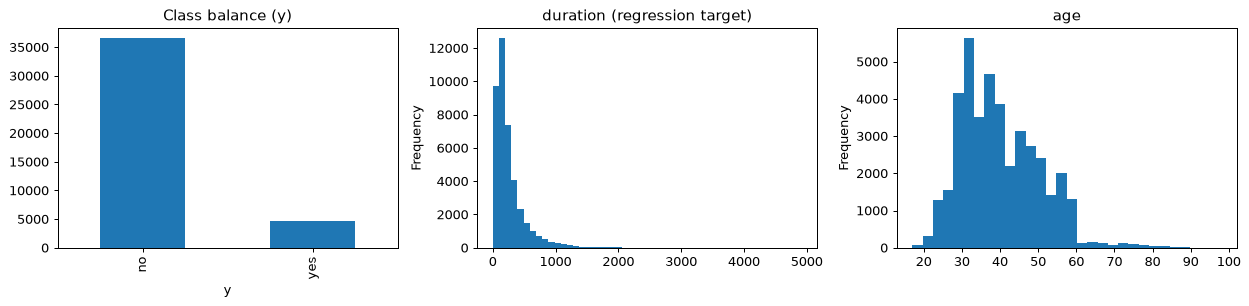

In [ ]:
print("Missing values (NaN):", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
display(df.describe().T)
print("\nTarget distribution (y):")
print(df["y"].value_counts(normalize=True).round(4))
print("\nColumns containing the placeholder 'unknown':")
print({c: int((df[c] == "unknown").sum()) for c in df.select_dtypes("object") if (df[c] == "unknown").any()})
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
df["y"].value_counts().plot.bar(ax=ax[0], title="Class balance (y)")
df["duration"].plot.hist(bins=50, ax=ax[1], title="duration (regression target)")
df["age"].plot.hist(bins=30, ax=ax[2], title="age")
plt.tight_layout(); plt.show()

**Explanation**

- We count NaN values and duplicates to learn how clean the data already is (duplicates were removed upstream).
- describe() gives mean, spread and range of each numeric feature, exposing skew such as the large pdays value 999.
- The target distribution shows y is imbalanced (about 89% 'no'), so accuracy alone will be misleading.
- Missing values in this dataset are hidden as the string 'unknown', which we count column by column.
- The plots show the class imbalance and the right-skewed duration, our regression target.
- These findings drive the preprocessing choices in the next section.

## 5. Data preprocessing and `preprocessed_dataset.csv` generation

In [ ]:
data = df.copy()
# 1. 'unknown' is a disguised missing value -> NaN -> impute with the column mode
cat_cols = data.select_dtypes("object").columns.drop("y")
data[cat_cols] = data[cat_cols].replace("unknown", np.nan)
for c in cat_cols:
    data[c] = data[c].fillna(data[c].mode()[0])
# 2. pdays == 999 means "never contacted" -> separate flag, then neutral value 0
data["pdays_never"] = (data["pdays"] == 999).astype(int)
data.loc[data["pdays"] == 999, "pdays"] = 0
# 3. Encode: target to 0/1, categoricals to one-hot
data["y"] = (data["y"] == "yes").astype(int)
data = pd.get_dummies(data, columns=list(cat_cols), drop_first=True, dtype=int)
data.to_csv("preprocessed_dataset.csv", index=False)
print("Saved preprocessed_dataset.csv with shape", data.shape)
print("Remaining NaN:", int(data.isna().sum().sum()))
display(data.head())

Saved preprocessed_dataset.csv with shape (41176, 49)
Remaining NaN: 0


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,56,261,1,0,0,1.1,93.994,-36.4,4.857,5191.0,...,1,0,0,0,1,0,0,0,1,0
1,57,149,1,0,0,1.1,93.994,-36.4,4.857,5191.0,...,1,0,0,0,1,0,0,0,1,0
2,37,226,1,0,0,1.1,93.994,-36.4,4.857,5191.0,...,1,0,0,0,1,0,0,0,1,0
3,40,151,1,0,0,1.1,93.994,-36.4,4.857,5191.0,...,1,0,0,0,1,0,0,0,1,0
4,56,307,1,0,0,1.1,93.994,-36.4,4.857,5191.0,...,1,0,0,0,1,0,0,0,1,0


**Explanation**

- The placeholder 'unknown' is converted to NaN and imputed with the most frequent category of each column.
- pdays = 999 (never contacted) would distort distance-based and linear models, so it becomes a binary flag plus a neutral 0.
- The target y is mapped to 1 (yes) / 0 (no) so every classifier can use it.
- One-hot encoding with drop_first=True converts categoricals into numeric columns without redundant dummies.
- The final table has no NaN and only numeric columns, and is written to preprocessed_dataset.csv as a separate output.
- Scaling is deferred to fits on the training split only, which prevents data leakage.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ---- Regression task: predict call duration (seconds) ----
Xr = data.drop(columns=["duration", "y"]).assign(y_flag=data["y"])
yr = data["duration"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=42)
sr = StandardScaler().fit(Xr_tr)
Xr_tr_s, Xr_te_s = sr.transform(Xr_tr), sr.transform(Xr_te)

# ---- Classification task: predict y. duration is dropped: it is only known AFTER the call (leakage) ----
Xc = data.drop(columns=["duration", "y"])
yc = data["y"]
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.2, random_state=42, stratify=yc)
sc = StandardScaler().fit(Xc_tr)
Xc_tr_s, Xc_te_s = sc.transform(Xc_tr), sc.transform(Xc_te)

# Subsamples for the slow from-scratch models and kernel SVMs
rng = np.random.RandomState(0)
idx_r = rng.choice(len(Xr_tr), 3000, replace=False)
idx_c = rng.choice(len(Xc_tr), 3000, replace=False)
print("Regression  train/test:", Xr_tr.shape, Xr_te.shape)
print("Classification train/test:", Xc_tr.shape, Xc_te.shape, "| positive rate", round(yc_tr.mean(), 3))

Regression  train/test: (32940, 48) (8236, 48)
Classification train/test: (32940, 47) (8236, 47) | positive rate 0.113


**Explanation**

- Regression predicts the numeric duration from all other columns; classification predicts the binary y.
- duration is excluded from the classifier because it is only known after the call ends, which would leak the answer.
- An 80/20 train/test split is made; the classification split is stratified so both parts keep the 11% positive rate.
- StandardScaler is fitted on the training part only and then applied to both parts, avoiding test-set leakage.
- Smaller 3000-row subsamples are prepared for the from-scratch models and kernel SVMs, which are expensive on 33k rows.
- All later sections reuse these exact splits so model comparisons are fair.

## 5. Preprocessing (summary)

Missing `unknown` values were imputed with the column mode, `pdays=999` became a *never contacted* flag, categoricals were one-hot encoded and the cleaned table was saved as `preprocessed_dataset.csv` (the code is in the notebook and omitted from this report). An 80/20 train/test split with standard scaling fitted on the training part was used for every model.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, confusion_matrix, log_loss, hinge_loss)
reg_results, clf_results = {}, {}
reg_preds, clf_preds, clf_scores = {}, {}, {}

def eval_reg(name, y_true, y_pred):
    reg_results[name] = dict(MSE=mean_squared_error(y_true, y_pred), MAE=mean_absolute_error(y_true, y_pred),
                             R2=r2_score(y_true, y_pred))
    reg_preds[name] = np.asarray(y_pred)
    print(f"{name:32s} MSE={reg_results[name]['MSE']:11.1f}  MAE={reg_results[name]['MAE']:7.2f}  R2={reg_results[name]['R2']:.4f}")

def eval_clf(name, y_true, y_pred, score, train_acc=None, kind="prob", train_score=None, y_train=None):
    # Loss = log loss of P(class 1), clipped to [0.001, 0.999]. SVM margins are first turned into probabilities by
    # Platt scaling (a logistic fit on the training scores) so every model has a comparable log loss; hinge loss is kept too.
    hinge = np.nan
    if kind == "margin":
        hinge = hinge_loss(y_true, score)
        platt = LogisticRegression().fit(np.reshape(train_score, (-1, 1)), y_train)
        prob = platt.predict_proba(np.reshape(score, (-1, 1)))[:, 1]
    else:
        prob = score
    loss = log_loss(y_true, np.clip(prob, 1e-3, 1 - 1e-3))
    clf_results[name] = dict(TrainAcc=train_acc, Accuracy=accuracy_score(y_true, y_pred),
                             Precision=precision_score(y_true, y_pred, zero_division=0),
                             Recall=recall_score(y_true, y_pred), F1=f1_score(y_true, y_pred),
                             AUC=roc_auc_score(y_true, score), Loss=loss, Hinge=hinge)
    clf_preds[name], clf_scores[name] = np.asarray(y_pred), np.asarray(score)
    r = clf_results[name]
    print(f"{name:30s} acc={r['Accuracy']:.4f} prec={r['Precision']:.3f} rec={r['Recall']:.3f} f1={r['F1']:.3f} auc={r['AUC']:.3f} loss={r['Loss']:.3f}")

**Explanation**

- Two helper functions compute metrics once, so every model is scored identically.
- Regression metrics: MSE (squares large errors), MAE (average absolute error) and R2 (variance explained).
- Classification metrics: accuracy, precision, recall, F1, ROC-AUC and loss, because accuracy alone hides the class imbalance.
- Loss is log loss of the predicted probability (clipped to 0.001-0.999); SVM margins are converted by Platt scaling, and hinge loss is also stored.
- Predictions and scores of every model are stored so later sections can draw ROC curves and confusion matrices.
- Using one shared evaluation path avoids inconsistent comparisons between from-scratch and library models.

In [ ]:
import matplotlib as mpl
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.labelsize": 9, "font.size": 9, "legend.frameon": False})
BEST, REST = "#1b9e77", "#9aa9ba"
PALETTE = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02", "#386cb0"]
CLF_COLS, CLF_LOWER = ["Accuracy", "Precision", "Recall", "F1", "AUC", "Loss"], ("Loss",)
REG_COLS, REG_LOWER = ["MSE", "MAE", "R2"], ("MSE", "MAE")

def rank_dot(ax, s, title, xlabel, higher_better=True, fmt="{:.3f}", top=None):
    # Lollipop chart sorted so the best model is on top and highlighted in green
    s = s.astype(float).sort_values(ascending=higher_better)
    if top: s = s.iloc[-top:]
    y, span = np.arange(len(s)), (s.max() - s.min()) or 1.0
    lo, hi = s.min() - .10 * span, s.max() + .25 * span
    col = [REST] * (len(s) - 1) + [BEST]
    ax.hlines(y, lo, s.values, color=col, lw=2); ax.scatter(s.values, y, c=col, s=55, zorder=3)
    for yi, v in zip(y, s.values):
        ax.text(v + .02 * span, yi, fmt.format(v), va="center", fontsize=8)
    ax.set_yticks(y); ax.set_yticklabels(s.index, fontsize=8); ax.set_xlim(lo, hi); ax.grid(axis="y", visible=False)
    ax.set_title(title); ax.set_xlabel(xlabel + ("  (higher = better)" if higher_better else "  (lower = better)"))

def heatmap(ax, df, lower=(), title=""):
    norm = (df - df.min()) / (df.max() - df.min() + 1e-12)
    for c in lower: norm[c] = 1 - norm[c]
    ax.imshow(norm.values, aspect="auto", cmap="YlGn", vmin=0, vmax=1); ax.grid(False)
    ax.set_xticks(range(df.shape[1])); ax.set_xticklabels(df.columns); ax.xaxis.tick_top()
    ax.set_yticks(range(df.shape[0])); ax.set_yticklabels(df.index, fontsize=8)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            v = df.iat[i, j]; ax.text(j, i, f"{v:,.0f}" if abs(v) >= 100 else f"{v:.3f}", ha="center", va="center",
                                      fontsize=7.5, color="white" if norm.iat[i, j] > .75 else "black")
    ax.set_title(title, pad=28)

def composite(df, lower=()):
    # Average rank over all metrics (1 = best); rank-based, so one extreme value cannot distort the result
    return pd.DataFrame({c: df[c].rank(ascending=(c in lower), method="min") for c in df.columns}).mean(1).sort_values()

def radar(ax, df_all, names, lower=(), title=""):
    norm = (df_all - df_all.min()) / (df_all.max() - df_all.min() + 1e-12)
    for c in lower: norm[c] = 1 - norm[c]
    ang = list(np.linspace(0, 2 * np.pi, df_all.shape[1], endpoint=False)); ang += ang[:1]
    for i, n in enumerate(names):
        v = norm.loc[n].tolist() + norm.loc[n].tolist()[:1]
        ax.plot(ang, v, lw=2, color=PALETTE[i], label=n); ax.fill(ang, v, alpha=.08, color=PALETTE[i])
    ax.set_xticks(ang[:-1]); ax.set_xticklabels([c + (" (inv.)" if c in lower else "") for c in df_all.columns], fontsize=8)
    ax.set_yticklabels([]); ax.set_ylim(0, 1); ax.set_title(title, pad=18); ax.legend(loc="upper center", bbox_to_anchor=(.5, -.08), fontsize=7.5, ncol=1)

def family(name, task):
    n = name.lower()
    if any(k in n for k in ["stacking", "voting", "adaboost", "random forest", "bagging"]): return "Ensemble"
    for k, f in [("svm", "SVM"), ("svc", "SVM"), ("knn", "KNN"), ("naive", "Naive Bayes"), (" nb", "Naive Bayes"),
                 ("tree", "Decision Tree"), ("logistic", "Logistic Regression"), ("linear", "Linear Regression")]:
        if k in n: return f
    return "Other"

**Explanation**

- These helpers give every comparison graph the same clean, professional style (no top/right borders, light grid, one colour palette).
- rank_dot draws a lollipop chart sorted so the best model is on top and highlighted in green; heatmap shows all metrics at once.
- composite computes each model's average rank across all metrics, which is robust to one extreme value such as a very large MSE.
- radar compares the top models on several metrics at once after min-max scaling, with error-type metrics inverted so outward is always better.
- family groups models (SVM, Decision Tree, KNN, Naive Bayes, Logistic, Linear, Ensemble) so the final charts can compare algorithms.
- Defining them once keeps the code short and the charts consistent across the whole report.

## 6. Regression: from scratch

Linear Regression (scratch GD)   MSE=    56882.3  MAE= 155.66  R2=0.1835


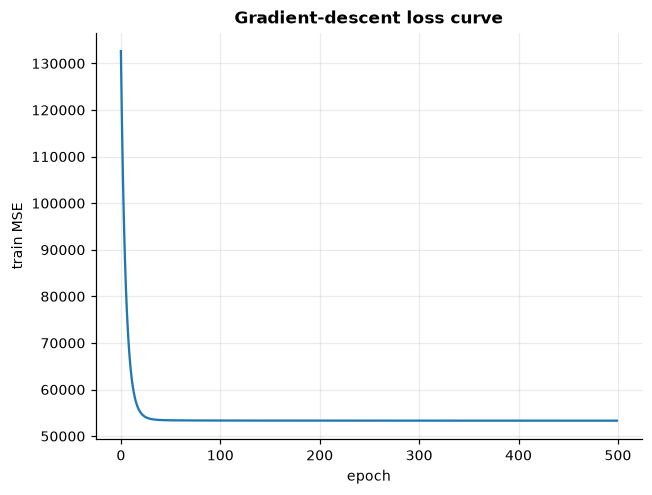

In [ ]:
class LinearRegressionGD:
    """Linear regression trained by batch gradient descent on the MSE loss (delta rule)."""
    def __init__(self, lr=0.05, epochs=500):
        self.lr, self.epochs = lr, epochs
    def fit(self, X, y):
        n, d = X.shape
        self.w, self.b, self.loss = np.zeros(d), 0.0, []
        for _ in range(self.epochs):
            err = X @ self.w + self.b - y
            self.w -= self.lr * (2 / n) * X.T @ err
            self.b -= self.lr * (2 / n) * err.sum()
            self.loss.append((err ** 2).mean())
        return self
    def predict(self, X):
        return X @ self.w + self.b

lin_gd = LinearRegressionGD().fit(Xr_tr_s, yr_tr.values)
pred = lin_gd.predict(Xr_te_s)
eval_reg("Linear Regression (scratch GD)", yr_te, pred)
plt.plot(lin_gd.loss); plt.xlabel("epoch"); plt.ylabel("train MSE"); plt.title("Gradient-descent loss curve"); plt.show()

**Explanation**

- The class implements linear regression with weights w and bias b learned by batch gradient descent.
- Each epoch computes the prediction error, then moves w and b opposite to the MSE gradient (the delta rule).
- Features are standardised, so one learning rate of 0.05 converges smoothly.
- We evaluate on the untouched test split using MSE, MAE and R2.
- The loss curve falls and flattens, which visually confirms convergence of gradient descent.

In [ ]:
class TreeScratch:
    """CART tree. mode: 'gini' | 'entropy' (classification) or 'mse' (regression)."""
    def __init__(self, mode="gini", max_depth=4, min_leaf=20, n_thr=8):
        self.mode, self.max_depth, self.min_leaf, self.n_thr = mode, max_depth, min_leaf, n_thr
    def _imp(self, y):
        if self.mode == "mse":
            return y.var()
        p = y.mean()
        if p in (0, 1):
            return 0.0
        return 1 - p**2 - (1-p)**2 if self.mode == "gini" else -(p*np.log2(p) + (1-p)*np.log2(1-p))
    def _leaf(self, y):
        return float(y.mean())   # mean target (regression) or class-1 probability (classification)
    def _build(self, X, y, depth):
        if depth >= self.max_depth or len(y) < 2 * self.min_leaf or self._imp(y) == 0:
            return {"leaf": self._leaf(y)}
        best, parent = None, self._imp(y)
        for j in range(X.shape[1]):
            for t in np.unique(np.percentile(X[:, j], np.linspace(10, 90, self.n_thr))):
                m = X[:, j] <= t
                if m.sum() < self.min_leaf or (~m).sum() < self.min_leaf:
                    continue
                gain = parent - (m.mean() * self._imp(y[m]) + (~m).mean() * self._imp(y[~m]))
                if best is None or gain > best[0]:
                    best = (gain, j, t, m)
        if best is None or best[0] <= 1e-9:
            return {"leaf": self._leaf(y)}
        _, j, t, m = best
        return {"f": j, "t": t, "L": self._build(X[m], y[m], depth+1), "R": self._build(X[~m], y[~m], depth+1)}
    def fit(self, X, y):
        self.root = self._build(np.asarray(X), np.asarray(y, dtype=float), 0); return self
    def _one(self, x, n):
        while "leaf" not in n:
            n = n["L"] if x[n["f"]] <= n["t"] else n["R"]
        return n["leaf"]
    def predict_value(self, X):
        return np.array([self._one(x, self.root) for x in np.asarray(X)])
    def predict(self, X):
        v = self.predict_value(X)
        return v if self.mode == "mse" else (v >= 0.5).astype(int)

t0 = time.time()
tree_r = TreeScratch(mode="mse", max_depth=5, min_leaf=30).fit(Xr_tr_s[idx_r], yr_tr.values[idx_r])
eval_reg("Regression Tree (scratch CART)", yr_te, tree_r.predict(Xr_te_s))
print("fit+predict seconds:", round(time.time() - t0, 1))

Regression Tree (scratch CART)   MSE=    55296.3  MAE= 152.12  R2=0.2063
fit+predict seconds: 0.1


**Explanation**

- TreeScratch is a recursive CART tree; each node stores a feature index, a threshold and two children.
- For regression the impurity is the variance (MSE); the best split is the one with the largest impurity reduction.
- Candidate thresholds are 8 percentiles per feature, and max_depth and min_leaf act as stopping rules against over-fitting.
- A leaf predicts the mean target of its samples; predict walks the if-else rules from the root to a leaf.
- To keep pure Python fast the tree is trained on a 3000-row subsample, then scored on the full test set.
- The same class is reused for classification with Gini or Entropy in Section 9.

In [ ]:
class KNNScratch:
    # k-Nearest Neighbours without libraries: Euclidean distance + average of the k closest training targets
    def __init__(self, k=15, task="clf"):
        self.k, self.task = k, task
    def fit(self, X, y):
        self.X, self.y = np.asarray(X, float), np.asarray(y, float)
        self.sq = (self.X ** 2).sum(1)
        return self
    def predict_value(self, Xq, chunk=500):
        Xq, out = np.asarray(Xq, float), np.empty(len(Xq))
        for i in range(0, len(Xq), chunk):
            q = Xq[i:i + chunk]
            d = (q ** 2).sum(1)[:, None] - 2 * q @ self.X.T + self.sq[None, :]      # squared distances to all training rows
            nn = np.argpartition(d, self.k, axis=1)[:, :self.k]                      # indices of the k nearest rows
            out[i:i + chunk] = self.y[nn].mean(1)                                    # mean target / fraction of class 1
        return out
    def predict(self, Xq):
        v = self.predict_value(Xq)
        return v if self.task == "reg" else (v >= 0.5).astype(int)

t0 = time.time()
knn_r = KNNScratch(k=15, task="reg").fit(Xr_tr_s, yr_tr.values)
eval_reg("KNN Regressor (scratch)", yr_te, knn_r.predict(Xr_te_s))
print("seconds:", round(time.time() - t0, 1))

KNN Regressor (scratch)          MSE=    62293.6  MAE= 159.71  R2=0.1058
seconds: 3.2


**Explanation**

- KNN stores the training data and predicts for a new row from its k closest training rows; there is no training phase.
- Distances use the identity |a-b|^2 = |a|^2 - 2ab + |b|^2, so a whole batch of 500 test rows is processed with one matrix product.
- np.argpartition finds the k smallest distances without fully sorting, which is much faster than a full sort.
- For regression the prediction is the mean target of the k neighbours; for classification it is the fraction of positive neighbours.
- Features are standardised first, because KNN is distance based and large-valued columns would otherwise dominate.
- The same class is reused for classification in Section 9, with task='clf' and a 0.5 voting threshold.

## 7. Regression: library models

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

lr = LinearRegression().fit(Xr_tr_s, yr_tr)
eval_reg("Linear Regression (sklearn)", yr_te, lr.predict(Xr_te_s))

for d in [2, 4, 6, 8]:
    m = DecisionTreeRegressor(max_depth=d, min_samples_leaf=20, random_state=42).fit(Xr_tr, yr_tr)
    eval_reg(f"Decision Tree Reg depth={d}", yr_te, m.predict(Xr_te))
dt_reg = DecisionTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=42).fit(Xr_tr, yr_tr)

Linear Regression (sklearn)      MSE=    56845.8  MAE= 155.62  R2=0.1840
Decision Tree Reg depth=2        MSE=    54512.0  MAE= 151.65  R2=0.2175
Decision Tree Reg depth=4        MSE=    53116.7  MAE= 148.48  R2=0.2376


Decision Tree Reg depth=6        MSE=    52857.4  MAE= 147.99  R2=0.2413


Decision Tree Reg depth=8        MSE=    53182.9  MAE= 148.05  R2=0.2366


**Explanation**

- sklearn's LinearRegression solves the same problem as our scratch version using the exact least-squares solution.
- Its metrics should match the gradient-descent model closely, which validates our scratch implementation.
- DecisionTreeRegressor is trained at several max_depth values to show the bias-variance trade-off.
- Shallow trees under-fit, while very deep trees start to over-fit; min_samples_leaf=20 limits leaf noise.
- Trees need no scaling, so they are fitted on the raw features.
- We keep depth 6 as the library regression tree for later comparisons.

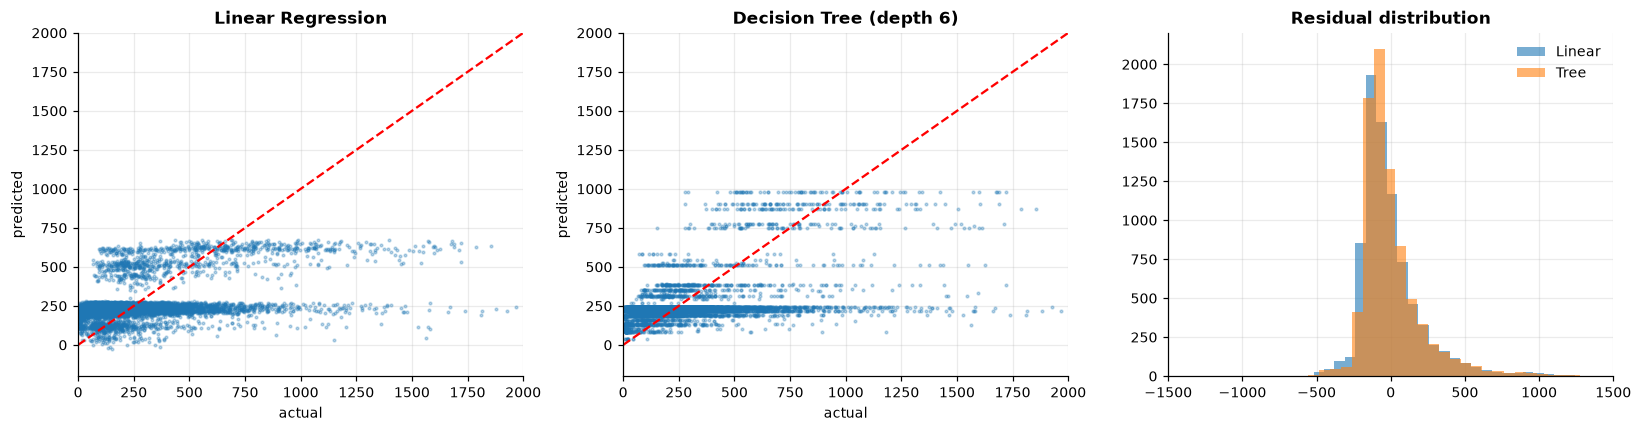

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (nm, p) in zip(ax[:2], [("Linear Regression", lr.predict(Xr_te_s)), ("Decision Tree (depth 6)", dt_reg.predict(Xr_te))]):
    a.scatter(yr_te, p, s=3, alpha=.3); a.plot([0, 2000], [0, 2000], "r--")
    a.set_xlim(0, 2000); a.set_ylim(-200, 2000); a.set_xlabel("actual"); a.set_ylabel("predicted"); a.set_title(nm)
ax[2].hist(yr_te - lr.predict(Xr_te_s), bins=60, alpha=.6, label="Linear")
ax[2].hist(yr_te - dt_reg.predict(Xr_te), bins=60, alpha=.6, label="Tree")
ax[2].set_title("Residual distribution"); ax[2].set_xlim(-1500, 1500); ax[2].legend()
plt.tight_layout(); plt.show()

**Explanation**

- The first two panels plot predicted against actual duration; points on the red dashed line are perfect predictions.
- Linear regression produces a diffuse cloud because it can only fit a single straight relationship.
- The tree's predictions form horizontal bands, since each leaf outputs one constant value.
- The residual histogram shows the error spread; a narrower, more centred histogram means a better model.
- Both models struggle with long calls, which shows duration is inherently hard to predict from this data.

KNN Regressor (sklearn)          MSE=    62150.7  MAE= 158.46  R2=0.1079


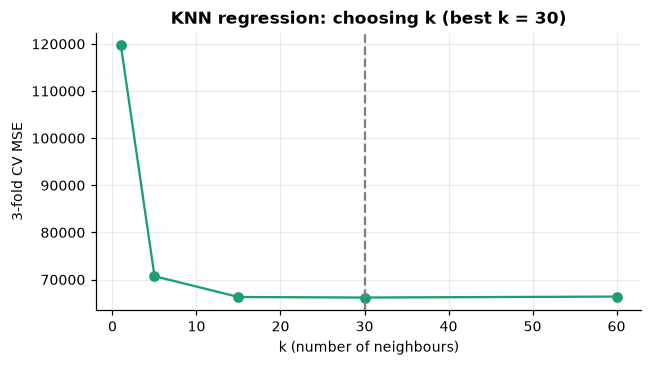

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score
ks = [1, 5, 15, 30, 60]
cv_mse = [-cross_val_score(KNeighborsRegressor(k), Xr_tr_s[idx_r], yr_tr.values[idx_r], cv=3, scoring="neg_mean_squared_error").mean() for k in ks]
best_k_reg = ks[int(np.argmin(cv_mse))]
knn_reg = KNeighborsRegressor(best_k_reg, n_jobs=-1).fit(Xr_tr_s, yr_tr)
eval_reg("KNN Regressor (sklearn)", yr_te, knn_reg.predict(Xr_te_s))
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(ks, cv_mse, "o-", color=PALETTE[0]); ax.axvline(best_k_reg, ls="--", color="grey")
ax.set_xlabel("k (number of neighbours)"); ax.set_ylabel("3-fold CV MSE"); ax.set_title(f"KNN regression: choosing k (best k = {best_k_reg})")
plt.tight_layout(); plt.show()

**Explanation**

- KNeighborsRegressor is the library version of our scratch KNN; k is chosen by 3-fold cross-validation on the training data only.
- Small k follows noise (high variance); large k over-smooths (high bias), so the CV curve is U-shaped.
- The dashed line marks the k with the lowest cross-validated MSE, which is then used to fit on the full training set.
- Because k is chosen without touching the test split, the final test score is an honest estimate.
- Its error is compared with the scratch version in the next section to confirm both implementations agree.

,MSE,MAE,R2
Decision Tree Reg depth=6,52857.370,147.987,0.241
Decision Tree Reg depth=4,53116.654,148.482,0.238
Decision Tree Reg depth=8,53182.864,148.054,0.237
Decision Tree Reg depth=2,54511.986,151.648,0.218
Regression Tree (scratch CART),55296.264,152.119,0.206
Linear Regression (sklearn),56845.821,155.625,0.184
Linear Regression (scratch GD),56882.321,155.657,0.184
KNN Regressor (sklearn),62150.698,158.463,0.108
KNN Regressor (scratch),62293.648,159.709,0.106


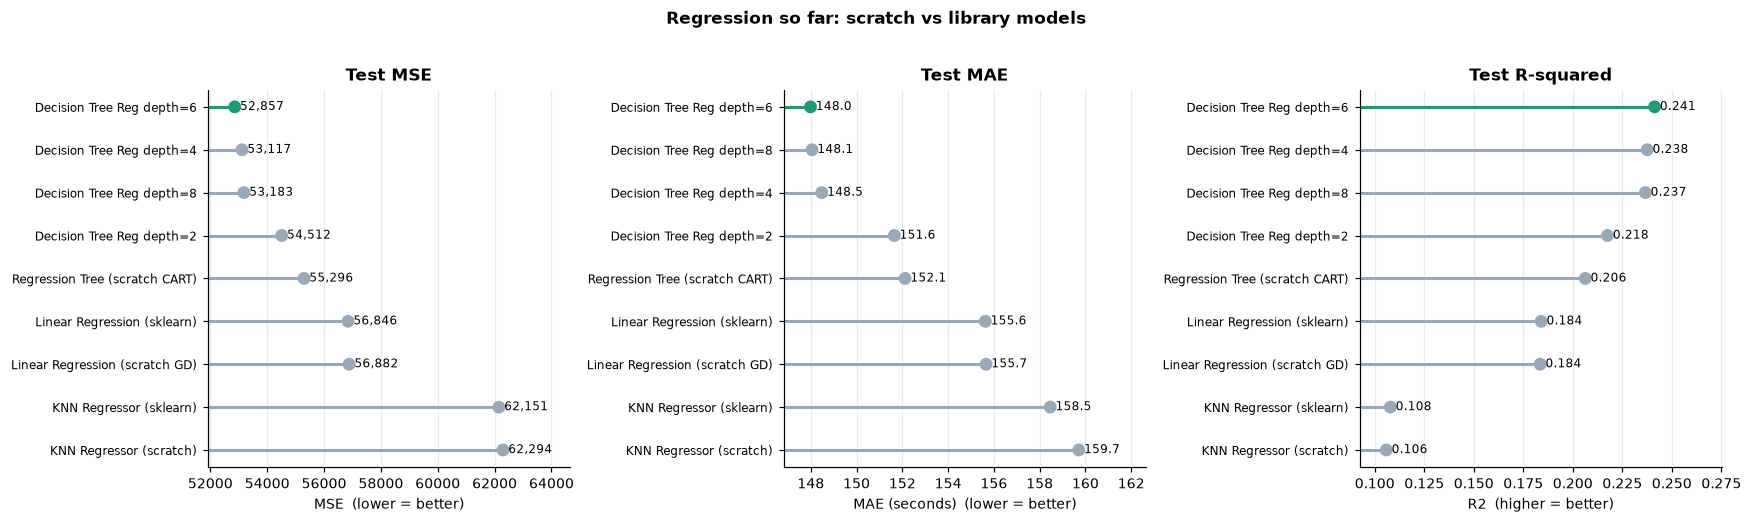

In [ ]:
R8 = pd.DataFrame(reg_results).T[REG_COLS]
display(R8.sort_values("MSE").round(3))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
rank_dot(ax[0], R8["MSE"], "Test MSE", "MSE", higher_better=False, fmt="{:,.0f}")
rank_dot(ax[1], R8["MAE"], "Test MAE", "MAE (seconds)", higher_better=False, fmt="{:.1f}")
rank_dot(ax[2], R8["R2"], "Test R-squared", "R2", higher_better=True)
fig.suptitle("Regression so far: scratch vs library models", fontweight="bold", y=1.02); plt.tight_layout(); plt.show()

**Explanation**

- The table lists MSE, MAE and R2 for every regression model trained so far, scratch and library together.
- Each lollipop panel ranks the models on one metric, with the best model highlighted in green.
- Scratch linear regression and scikit-learn linear regression land almost on top of each other, which validates the scratch code.
- The same holds for the scratch CART tree and KNN against their library versions, within normal sampling differences.
- R2 stays low for every model, so call duration is only partly predictable from the available features.

## 9. Classification: from scratch

In [ ]:
class LogisticRegressionGD:
    def __init__(self, lr=0.1, epochs=400):
        self.lr, self.epochs = lr, epochs
    def _sig(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -30, 30)))
    def fit(self, X, y):
        n, d = X.shape
        self.w, self.b, self.loss = np.zeros(d), 0.0, []
        for _ in range(self.epochs):
            p = self._sig(X @ self.w + self.b)
            self.w -= self.lr * X.T @ (p - y) / n
            self.b -= self.lr * (p - y).mean()
            self.loss.append(-np.mean(y*np.log(p+1e-9) + (1-y)*np.log(1-p+1e-9)))
        return self
    def predict_proba(self, X):
        return self._sig(X @ self.w + self.b)
    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

lg = LogisticRegressionGD().fit(Xc_tr_s, yc_tr.values)
eval_clf("Logistic Regression (scratch)", yc_te, lg.predict(Xc_te_s), lg.predict_proba(Xc_te_s), accuracy_score(yc_tr, lg.predict(Xc_tr_s)))

Logistic Regression (scratch)  acc=0.8978 prec=0.656 rec=0.195 f1=0.301 auc=0.798 loss=0.276


**Explanation**

- Logistic regression passes a linear score through the sigmoid to produce the probability of class 1.
- Gradient descent minimises the cross-entropy loss; the gradient is simply X transposed times (prediction minus label).
- The sigmoid input is clipped to avoid numerical overflow, and a small constant protects log(0).
- Predictions use a 0.5 probability threshold, and the model is scored on the unseen test split.
- Because 89% of labels are 'no', accuracy looks high, so precision, recall and AUC are the more informative columns.

In [ ]:
t0 = time.time()
tree_g = TreeScratch("gini", max_depth=4, min_leaf=30).fit(Xc_tr_s[idx_c], yc_tr.values[idx_c])
eval_clf("Decision Tree (scratch Gini)", yc_te, tree_g.predict(Xc_te_s), tree_g.predict_value(Xc_te_s),
         accuracy_score(yc_tr, tree_g.predict(Xc_tr_s)))
print("seconds:", round(time.time() - t0, 1))

Decision Tree (scratch Gini)   acc=0.8986 prec=0.693 rec=0.180 f1=0.286 auc=0.776 loss=0.287
seconds: 0.2


**Explanation**

- The same TreeScratch class now runs in classification mode, using Gini impurity 1 - p^2 - (1-p)^2.
- Leaves store the fraction of class-1 samples, and the predicted class is 1 when that fraction is at least 0.5.
- Depth 4 with min_leaf=30 keeps the tree small and easy to interpret.
- Training uses the 3000-row subsample for speed; evaluation still uses the full test split.
- The leaf probabilities double as scores, so ROC-AUC can be computed for this scratch tree.

In [ ]:
class LinearSVMScratch:
    """Soft-margin linear SVM: minimise 0.5*||w||^2 + C*mean(hinge) by sub-gradient descent."""
    def __init__(self, C=1.0, lr=0.01, epochs=300):
        self.C, self.lr, self.epochs = C, lr, epochs
    def fit(self, X, y01):
        y = np.where(y01 == 1, 1, -1)
        n, d = X.shape
        self.w, self.b = np.zeros(d), 0.0
        for e in range(self.epochs):
            viol = y * (X @ self.w + self.b) < 1                 # margin violators = support-vector candidates
            gw = self.w - self.C * (y[viol, None] * X[viol]).sum(0) / n
            gb = -self.C * y[viol].sum() / n
            step_ = self.lr / (1 + 0.01 * e)
            self.w -= step_ * gw; self.b -= step_ * gb
        return self
    def decision_function(self, X):
        return X @ self.w + self.b
    def predict(self, X):
        return (self.decision_function(X) >= 0).astype(int)

svm_s = LinearSVMScratch(C=5).fit(Xc_tr_s, yc_tr.values)
eval_clf("Linear SVM (scratch)", yc_te, svm_s.predict(Xc_te_s), svm_s.decision_function(Xc_te_s),
         accuracy_score(yc_tr, svm_s.predict(Xc_tr_s)), kind="margin",
         train_score=svm_s.decision_function(Xc_tr_s), y_train=yc_tr.values)
print("Margin width 2/||w|| =", round(2 / np.linalg.norm(svm_s.w), 3))

Linear SVM (scratch)           acc=0.8956 prec=0.611 rec=0.202 f1=0.303 auc=0.730 loss=0.323
Margin width 2/||w|| = 8.838


**Explanation**

- The SVM looks for the hyperplane w.x + b = 0 that has the widest margin, 2/||w||, between the two classes.
- The loss is 0.5*||w||^2 plus C times the hinge loss, which penalises points inside the margin or misclassified.
- Sub-gradient descent updates w only from margin violators, so the final solution depends on support-vector-like points.
- C controls the soft margin: a large C punishes violations heavily, a small C tolerates them for a wider margin.
- The learning rate decays each epoch to help convergence, and the printed width shows the resulting margin.

In [ ]:
t0 = time.time()
knn_c = KNNScratch(k=15, task="clf").fit(Xc_tr_s, yc_tr.values)
pk = knn_c.predict_value(Xc_te_s)
eval_clf("KNN (scratch)", yc_te, (pk >= 0.5).astype(int), pk, accuracy_score(yc_tr, knn_c.predict(Xc_tr_s)))
print("seconds:", round(time.time() - t0, 1))

KNN (scratch)                  acc=0.8956 prec=0.596 rec=0.227 f1=0.329 auc=0.767 loss=0.337
seconds: 14.7


**Explanation**

- The KNNScratch class from Section 6 is reused for classification with k=15 neighbours.
- The score of a test row is the fraction of its 15 nearest neighbours that subscribed, and the class is 1 when that fraction is at least 0.5.
- That fraction doubles as a probability, so log loss and ROC-AUC can be computed for the scratch model.
- Train accuracy is measured on the training rows themselves (each row is its own nearest neighbour), so it is optimistic.
- KNN is slow at prediction time because every test row is compared with all 33k training rows.

In [ ]:
class GaussianNBScratch:
    # Gaussian Naive Bayes without libraries: P(class | x) is proportional to P(class) * product of N(x_j | mean, var) over features
    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y)
        self.classes = np.unique(y)
        self.logprior = np.log(np.array([(y == c).mean() for c in self.classes]))
        self.mu = np.array([X[y == c].mean(0) for c in self.classes])
        self.var = np.array([X[y == c].var(0) for c in self.classes]) + 1e-9 * X.var(0).max()   # smoothing avoids zero variance
        return self
    def _joint_log(self, X):
        X = np.asarray(X, float)[:, None, :]
        ll = -0.5 * (np.log(2 * np.pi * self.var)[None] + (X - self.mu[None]) ** 2 / self.var[None]).sum(2)
        return ll + self.logprior
    def predict_proba(self, X):
        j = self._joint_log(X); j -= j.max(1, keepdims=True)
        p = np.exp(j); return p / p.sum(1, keepdims=True)
    def predict(self, X):
        return self.classes[self._joint_log(X).argmax(1)]

nb_s = GaussianNBScratch().fit(Xc_tr_s, yc_tr.values)
eval_clf("Gaussian NB (scratch)", yc_te, nb_s.predict(Xc_te_s), nb_s.predict_proba(Xc_te_s)[:, 1], accuracy_score(yc_tr, nb_s.predict(Xc_tr_s)))

Gaussian NB (scratch)          acc=0.7555 prec=0.273 rec=0.703 f1=0.393 auc=0.774 loss=1.124


**Explanation**

- Naive Bayes applies Bayes' rule and assumes the features are independent given the class, so the likelihood is a product over features.
- For each class we store the prior probability and the mean and variance of every feature; training is a single pass over the data.
- Prediction sums log-probabilities (not raw probabilities) to avoid numerical underflow, then picks the class with the larger total.
- A tiny variance smoothing term prevents division by zero for features that are constant within a class.
- The independence assumption is violated here because many one-hot columns are correlated, so the probabilities are over-confident and loss is high.

## 10. Classification: library models

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC

def run(name, model, scaled=True, score="proba"):
    Xtr, Xte = (Xc_tr_s, Xc_te_s) if scaled else (Xc_tr, Xc_te)
    model.fit(Xtr, yc_tr)
    s = model.predict_proba(Xte)[:, 1] if score == "proba" else model.decision_function(Xte)
    eval_clf(name, yc_te, model.predict(Xte), s, accuracy_score(yc_tr, model.predict(Xtr)), kind="prob" if score == "proba" else "margin",
             train_score=None if score == "proba" else model.decision_function(Xtr), y_train=yc_tr.values)
    return model

logreg = run("Logistic Regression (sklearn)", LogisticRegression(max_iter=1000))
dt_clf = run("Decision Tree (sklearn, depth 5)", DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42), scaled=False)
lsvc = run("LinearSVC (sklearn)", LinearSVC(C=1, max_iter=5000), score="dec")

Logistic Regression (sklearn)  acc=0.8984 prec=0.652 rec=0.210 f1=0.318 auc=0.800 loss=0.274


Decision Tree (sklearn, depth 5) acc=0.9013 prec=0.655 rec=0.262 f1=0.374 auc=0.791 loss=0.271


LinearSVC (sklearn)            acc=0.8993 prec=0.680 rec=0.202 f1=0.311 auc=0.797 loss=0.279


**Explanation**

- A small run() helper fits a model, scores it on the test split and records the metrics.
- LogisticRegression and LinearSVC are the library versions of our scratch linear models; both use scaled features.
- DecisionTreeClassifier is limited to depth 5 with at least 20 samples per leaf to control over-fitting.
- Train accuracy is stored too, so a large train-test gap flags over-fitting.
- The scratch and library results should be close, which shows the scratch code behaves correctly.

In [ ]:
from sklearn.svm import SVC
for name, mdl in [("SVC linear kernel", SVC(kernel="linear", C=1)),
                  ("SVC poly kernel (deg 3)", SVC(kernel="poly", degree=3, C=1)),
                  ("SVC RBF kernel", SVC(kernel="rbf", C=1))]:
    t0 = time.time()
    mdl.fit(Xc_tr_s[idx_c], yc_tr.values[idx_c])
    eval_clf(name, yc_te, mdl.predict(Xc_te_s), mdl.decision_function(Xc_te_s), accuracy_score(yc_tr.values[idx_c], mdl.predict(Xc_tr_s[idx_c])), kind="margin",
             train_score=mdl.decision_function(Xc_tr_s[idx_c]), y_train=yc_tr.values[idx_c])
    print("   support vectors:", mdl.n_support_.sum(), "| seconds:", round(time.time() - t0, 1))

SVC linear kernel              acc=0.8952 prec=0.616 rec=0.185 f1=0.285 auc=0.670 loss=0.325
   support vectors: 1395 | seconds: 0.9


SVC poly kernel (deg 3)        acc=0.8929 prec=0.564 rec=0.220 f1=0.316 auc=0.692 loss=0.474
   support vectors: 967 | seconds: 0.7


SVC RBF kernel                 acc=0.8955 prec=0.643 rec=0.163 f1=0.260 auc=0.729 loss=0.350
   support vectors: 1046 | seconds: 1.9


**Explanation**

- SVC solves the full kernel SVM; we try linear, polynomial (degree 3) and RBF kernels.
- Kernels let an SVM draw non-linear boundaries by implicitly mapping features into a higher-dimensional space.
- Kernel SVM training is roughly quadratic in sample size, so we train on the 3000-row subsample.
- n_support_ reports how many training points lie on or inside the margin and therefore define the boundary.
- Features are scaled, since SVMs rely on distances and would otherwise be dominated by large-valued columns.

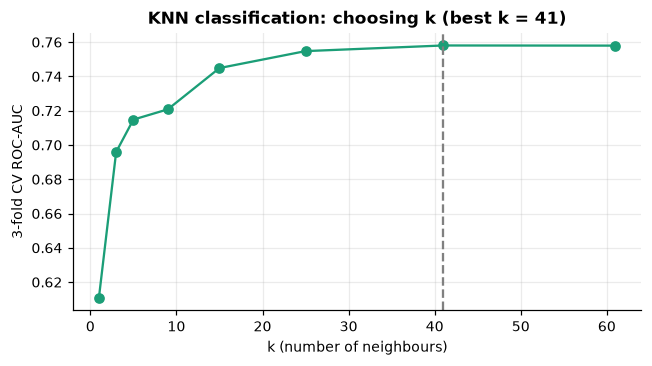

KNN (sklearn)                  acc=0.8970 prec=0.625 rec=0.216 f1=0.321 auc=0.778 loss=0.298


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
ks = [1, 3, 5, 9, 15, 25, 41, 61]
cv_auc = [cross_val_score(KNeighborsClassifier(k), Xc_tr_s[idx_c], yc_tr.values[idx_c], cv=3, scoring="roc_auc").mean() for k in ks]
best_k = ks[int(np.argmax(cv_auc))]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(ks, cv_auc, "o-", color=PALETTE[0]); ax.axvline(best_k, ls="--", color="grey")
ax.set_xlabel("k (number of neighbours)"); ax.set_ylabel("3-fold CV ROC-AUC"); ax.set_title(f"KNN classification: choosing k (best k = {best_k})")
plt.tight_layout(); plt.show()
knn_lib = run("KNN (sklearn)", KNeighborsClassifier(best_k, n_jobs=-1))

**Explanation**

- KNeighborsClassifier is the library version; k is picked by 3-fold cross-validated ROC-AUC using only training data.
- Very small k memorises noise, while very large k pushes every prediction toward the majority class 'no'.
- The chart marks the best k, and the model is then refitted on the full scaled training set.
- run() scores it on the untouched test split exactly like the other library models.
- Its metrics can be compared with the scratch KNN (k=15) to confirm the two implementations agree.

In [ ]:
from sklearn.naive_bayes import GaussianNB, BernoulliNB
nb_g = run("Gaussian NB (sklearn)", GaussianNB())
nb_b = run("Bernoulli NB (sklearn)", BernoulliNB(binarize=0.0))

Gaussian NB (sklearn)          acc=0.7555 prec=0.273 rec=0.703 f1=0.393 auc=0.774 loss=1.124
Bernoulli NB (sklearn)         acc=0.8267 prec=0.335 rec=0.547 f1=0.416 auc=0.775 loss=0.564


**Explanation**

- GaussianNB is the library twin of our scratch Naive Bayes and should reproduce its metrics almost exactly.
- BernoulliNB treats each feature as a yes/no variable; with binarize=0.0 on standardised data it asks whether a value is above or below the training mean.
- Naive Bayes is extremely fast to train and predict, because it only stores per-class means and variances.
- Its independence assumption makes probabilities over-confident, which usually shows up as a high log loss despite a reasonable AUC.
- Both models are scored with the same run() helper so they are directly comparable with SVM, trees and KNN.

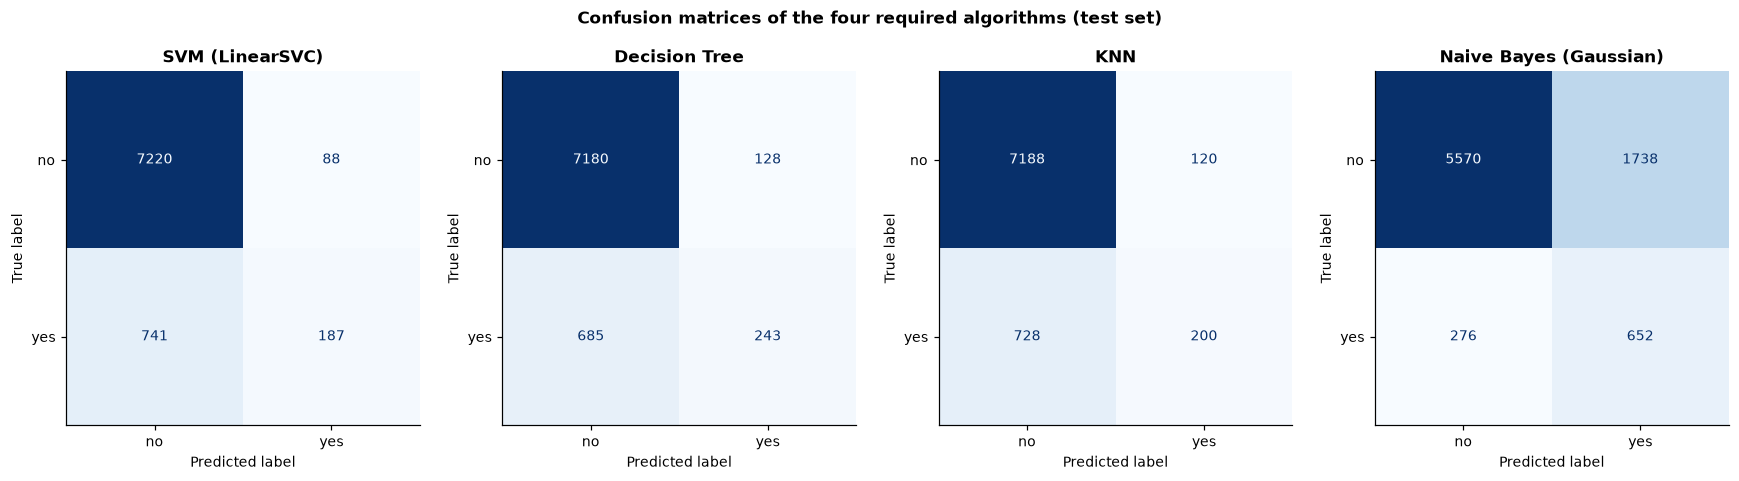

,Accuracy,Precision,Recall,F1,AUC,Loss
SVM (LinearSVC),0.8993,0.6800,0.2015,0.3109,0.7966,0.2785
Decision Tree,0.9013,0.6550,0.2619,0.3741,0.7913,0.2713
KNN,0.8970,0.6250,0.2155,0.3205,0.7784,0.2983
Naive Bayes (Gaussian),0.7555,0.2728,0.7026,0.3930,0.7739,1.1240


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
focus = {"SVM (LinearSVC)": "LinearSVC (sklearn)", "Decision Tree": "Decision Tree (sklearn, depth 5)",
         "KNN": "KNN (sklearn)", "Naive Bayes (Gaussian)": "Gaussian NB (sklearn)"}
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, (label, nm) in zip(ax, focus.items()):
    ConfusionMatrixDisplay.from_predictions(yc_te, clf_preds[nm], ax=a, colorbar=False, cmap="Blues", display_labels=["no", "yes"])
    a.set_title(label); a.grid(False)
fig.suptitle("Confusion matrices of the four required algorithms (test set)", fontweight="bold", y=1.03); plt.tight_layout(); plt.show()
four = pd.DataFrame({k: clf_results[v] for k, v in focus.items()}).T[CLF_COLS].astype(float)
display(four.round(4))

**Explanation**

- A confusion matrix shows exactly where each algorithm errs: top-right cells are false alarms, bottom-left cells are missed subscribers.
- The four panels compare one library model each for SVM, Decision Tree, KNN and Naive Bayes on the same test set.
- With only 11% positives, every model has many missed subscribers, so recall and F1 matter more than accuracy here.
- Naive Bayes behaves differently from the others: it flags many more customers as 'yes', trading precision for recall.
- The table below the plots gives the exact accuracy, precision, recall, F1, AUC and loss for the four algorithms.

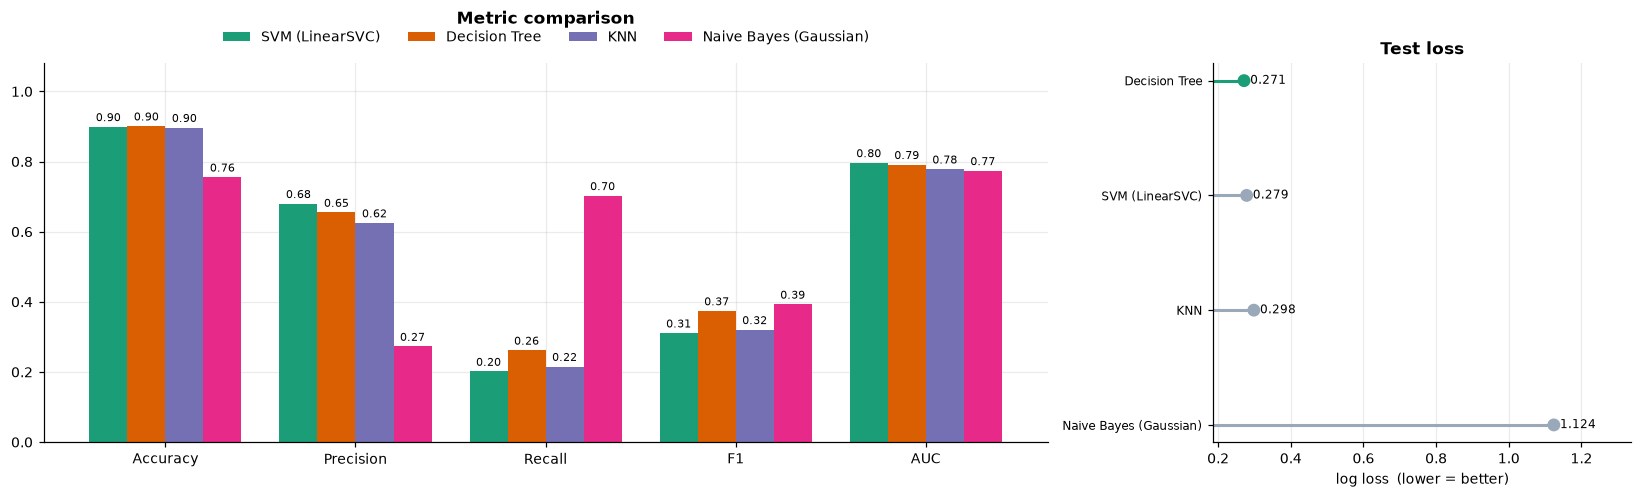

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [2.4, 1]})
cols = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
w = 0.2
for i, (nm, row) in enumerate(four.iterrows()):
    bars = ax[0].bar(np.arange(len(cols)) + (i - 1.5) * w, row[cols].values, w, label=nm, color=PALETTE[i])
    ax[0].bar_label(bars, fmt="%.2f", fontsize=7, padding=2)
ax[0].set_xticks(range(len(cols))); ax[0].set_xticklabels(cols); ax[0].set_ylim(0, 1.08); ax[0].legend(ncol=4, loc="upper center", bbox_to_anchor=(.5, 1.12))
ax[0].set_title("Metric comparison", pad=26)
rank_dot(ax[1], four["Loss"], "Test loss", "log loss", higher_better=False)
plt.tight_layout(); plt.show()

**Explanation**

- The grouped bars compare the four algorithms on accuracy, precision, recall, F1 and AUC side by side, each on a 0-1 scale.
- Accuracy bars look nearly identical because of the class imbalance, while recall and F1 bars separate the algorithms clearly.
- The right panel shows the log loss (SVM margins are Platt-scaled to probabilities), which is lower when predictions are correct and well calibrated.
- Naive Bayes produces extreme probabilities, so its log loss (about 1.12) is roughly four times that of the other three algorithms.
- Together the two panels show that no single metric is enough to choose an algorithm.

## 12. Decision Tree: Gini vs Entropy

train_acc         test_acc             auc        
criterion   entropy    gini  entropy    gini entropy    gini
depth                                                       
2            0.8995  0.8997   0.8984  0.8987  0.7535  0.7537
3            0.8995  0.9001   0.8984  0.8992  0.7789  0.7608
5            0.9027  0.9029   0.9008  0.9013  0.7912  0.7913
8            0.9060  0.9056   0.8987  0.8983  0.7973  0.8054
12           0.9079  0.9081   0.8964  0.8981  0.7855  0.7863

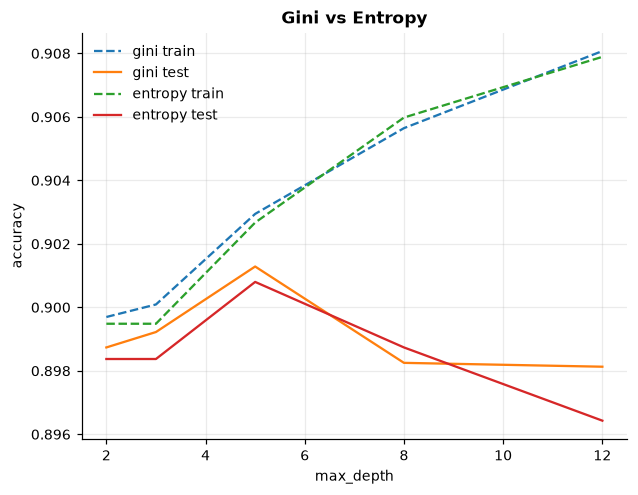

In [ ]:
rows = []
for crit in ["gini", "entropy"]:
    for d in [2, 3, 5, 8, 12]:
        m = DecisionTreeClassifier(criterion=crit, max_depth=d, min_samples_leaf=20, random_state=42).fit(Xc_tr, yc_tr)
        rows.append(dict(criterion=crit, depth=d, train_acc=m.score(Xc_tr, yc_tr), test_acc=m.score(Xc_te, yc_te),
                         auc=roc_auc_score(yc_te, m.predict_proba(Xc_te)[:, 1])))
ge = pd.DataFrame(rows)
display(ge.pivot(index="depth", columns="criterion", values=["train_acc", "test_acc", "auc"]).round(4))
for crit in ["gini", "entropy"]:
    s = ge[ge.criterion == crit]; plt.plot(s.depth, s.train_acc, "--", label=f"{crit} train"); plt.plot(s.depth, s.test_acc, label=f"{crit} test")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.legend(); plt.title("Gini vs Entropy"); plt.show()

**Explanation**

- Gini measures impurity as 1 - sum(p^2), while Entropy measures it as -sum(p log2 p); both reward pure leaves.
- We train trees with each criterion across five depths and record train accuracy, test accuracy and AUC.
- Train accuracy keeps rising with depth while test accuracy stalls or drops, which is over-fitting.
- The two criteria give very similar curves; Gini is slightly cheaper to compute because it has no logarithm.
- The best depth is where test AUC peaks, which justifies the shallow trees used earlier.

|--- nr.employed <= 5087.65
|   |--- pdays_never <= 0.50
|   |   |--- day_of_week_mon <= 0.50
|   |   |   |--- class: 1
|   |   |--- day_of_week_mon >  0.50
|   |   |   |--- class: 1
|   |--- pdays_never >  0.50
|   |   |--- contact_telephone <= 0.50
|   |   |   |--- class: 0
|   |   |--- contact_telephone >  0.50
|   |   |   |--- class: 0
|--- nr.employed >  5087.65
|   |--- cons.conf.idx <= -46.65
|   |   |--- euribor3m <= 1.53
|   |   |   |--- class: 0
|   |   |--- euribor3m >  1.53
|   |   |   |--- class: 0
|   |--- cons.conf.idx >  -46.65
|   |   |--- month_oct <= 0.50
|   |   |   |--- class: 0
|   |   |--- month_oct >  0.50
|   |   |   |--- class: 1



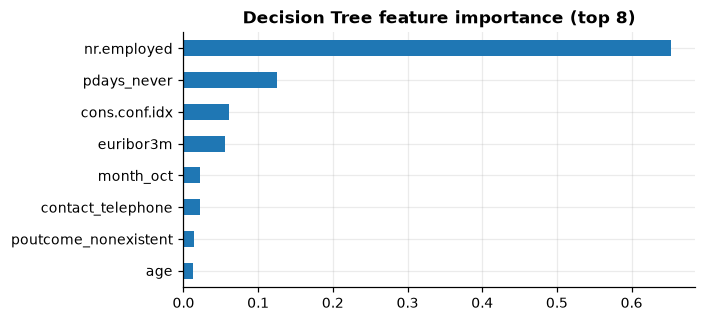

In [ ]:
from sklearn.tree import export_text
tree3 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=42).fit(Xc_tr, yc_tr)
print(export_text(tree3, feature_names=list(Xc.columns)))
imp = pd.Series(dt_clf.feature_importances_, index=Xc.columns).nlargest(8)
imp.sort_values().plot.barh(title="Decision Tree feature importance (top 8)", figsize=(6, 3)); plt.show()

**Explanation**

- export_text prints the tree as nested if-else rules, which shows a decision tree is just a set of readable conditions.
- Each line is a split on one feature threshold, and each leaf shows the predicted class.
- Economic indicators such as nr.employed and euribor3m usually appear near the root because they split the classes best.
- Feature importance sums each feature's impurity reduction over the tree and ranks them.
- This interpretability is a major advantage of trees compared with SVMs and ensembles.

## 13. SVM margin / kernel comparison

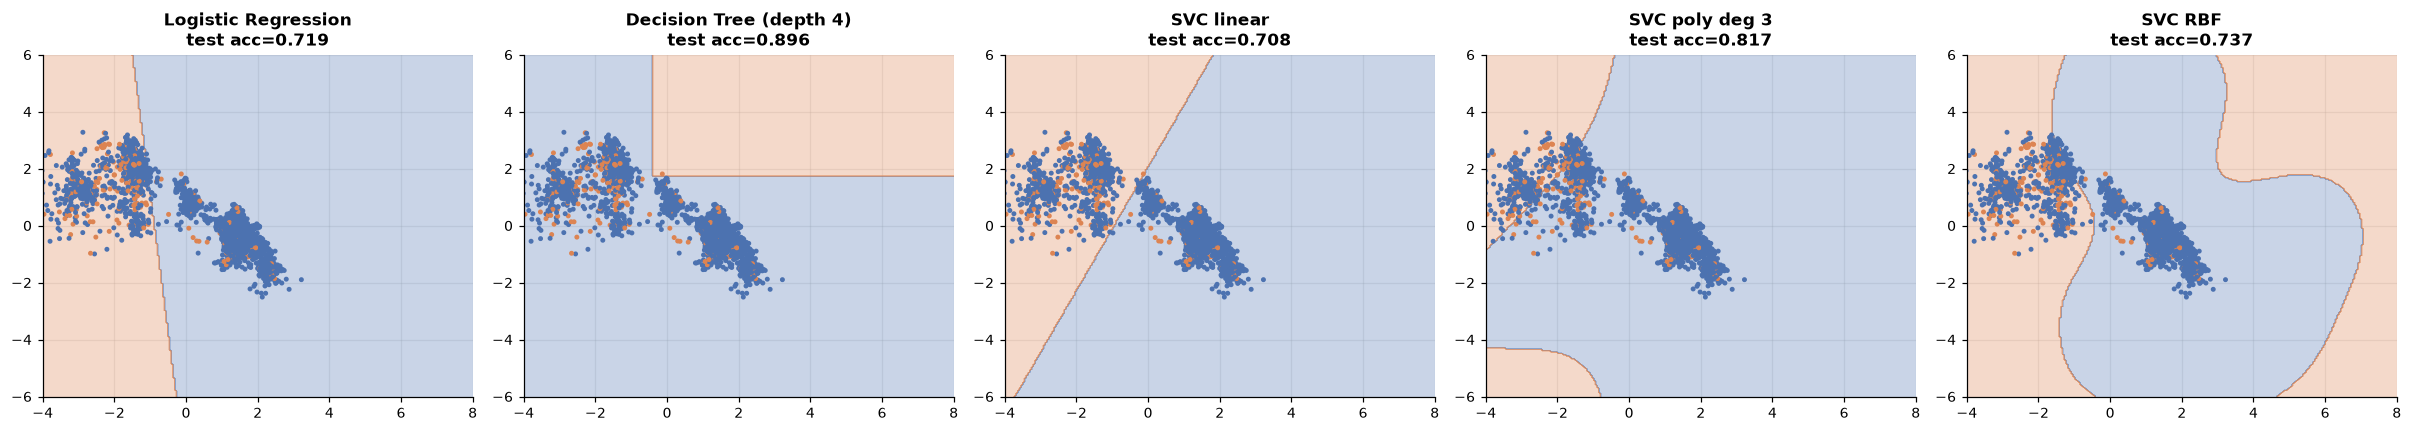

In [ ]:
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap

cm = ListedColormap(["#4c72b0", "#dd8452"])
pca = PCA(2, random_state=0).fit(Xc_tr_s)
Z_tr, Z_te = pca.transform(Xc_tr_s[idx_c]), pca.transform(Xc_te_s)
zy = yc_tr.values[idx_c]
xx, yy = np.meshgrid(np.linspace(-4, 8, 250), np.linspace(-6, 6, 250))
grid = np.c_[xx.ravel(), yy.ravel()]
models = {"Logistic Regression": LogisticRegression(class_weight="balanced"),
          "Decision Tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=0),
          "SVC linear": SVC(kernel="linear", class_weight="balanced"),
          "SVC poly deg 3": SVC(kernel="poly", degree=3, class_weight="balanced"),
          "SVC RBF": SVC(kernel="rbf", class_weight="balanced")}
fig, ax = plt.subplots(1, 5, figsize=(22, 4))
for a, (nm, m) in zip(ax, models.items()):
    m.fit(Z_tr, zy)
    a.contourf(xx, yy, m.predict(grid).reshape(xx.shape), alpha=.3, cmap=cm)
    a.scatter(Z_tr[:, 0], Z_tr[:, 1], c=zy, s=5, cmap=cm)
    a.set_title(f"{nm}\ntest acc={m.score(Z_te, yc_te):.3f}"); a.set_xlim(-4, 8); a.set_ylim(-6, 6)
plt.tight_layout(); plt.show()

**Explanation**

- To draw decision regions we project the standardised features onto two principal components, giving a plottable 2-D space.
- Each classifier is retrained in this 2-D space, and the coloured background shows the region assigned to each class.
- Logistic Regression and the linear SVC give a straight-line boundary, whereas the decision tree gives axis-aligned rectangles.
- The polynomial and RBF kernels bend the boundary to follow the data, which is the benefit of the kernel trick.
- class_weight='balanced' is used so the minority class is not ignored, which is why accuracy here is lower than elsewhere.

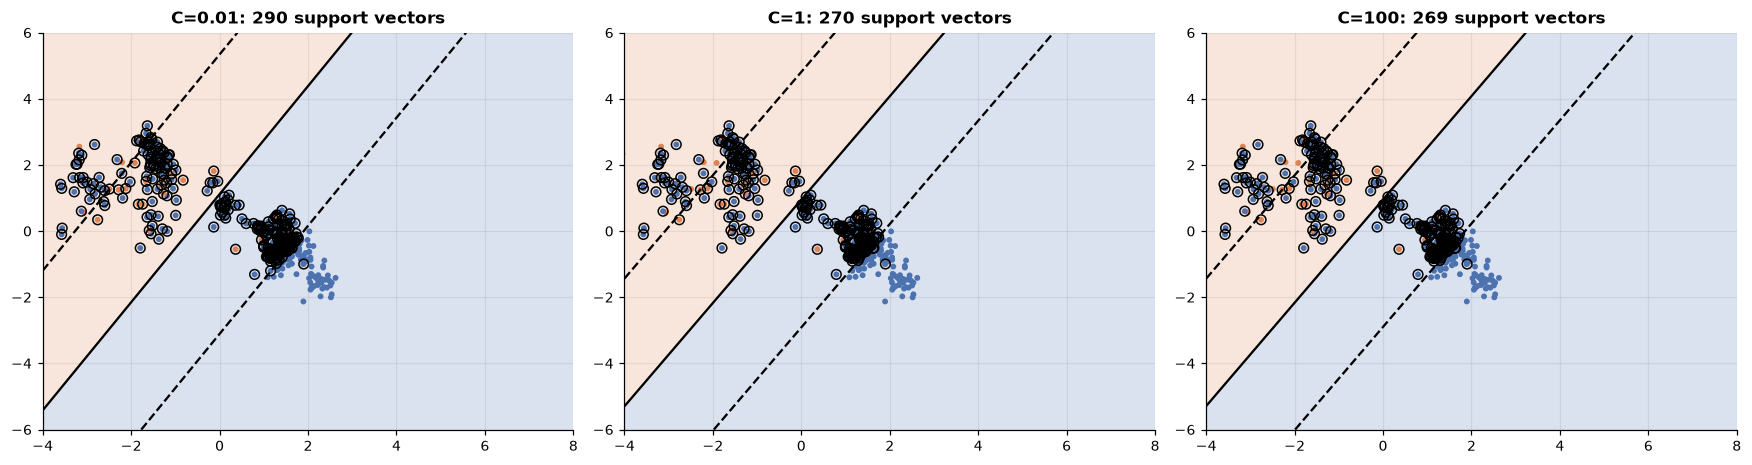

In [ ]:
Zs = Z_tr[:400]; zs = zy[:400]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for a, C in zip(ax, [0.01, 1, 100]):
    m = SVC(kernel="linear", C=C, class_weight="balanced").fit(Zs, zs)
    zz = m.decision_function(grid).reshape(xx.shape)
    a.contourf(xx, yy, zz > 0, alpha=.2, cmap=cm)
    a.contour(xx, yy, zz, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    a.scatter(Zs[:, 0], Zs[:, 1], c=zs, s=8, cmap=cm)
    a.scatter(*m.support_vectors_.T, s=40, facecolors="none", edgecolors="k")
    a.set_title(f"C={C}: {len(m.support_vectors_)} support vectors"); a.set_xlim(-4, 8); a.set_ylim(-6, 6)
plt.tight_layout(); plt.show()

**Explanation**

- The solid line is the separating hyperplane and the two dashed lines mark the margin edges at decision value +1 and -1.
- Circled points are support vectors: the training points on or inside the margin that alone determine the boundary.
- With a small C the margin is wide and many points violate it (soft margin), giving many support vectors.
- With a large C violations are punished harshly, so the margin narrows and fewer points are tolerated inside it.
- This panel visualises the slack / misclassification trade-off that C controls.

## 14. Bagging and bootstrap demonstration

In [ ]:
# Bootstrap sampling: draw n rows WITH replacement
n = len(Xc_tr)
boot = np.random.RandomState(1).choice(n, n, replace=True)
print("Unique rows in one bootstrap sample:", f"{len(np.unique(boot)) / n:.1%}", "(theory: 1 - 1/e = 63.2%)")

# Manual bagging of 25 trees (independent, parallelisable) with majority vote
rs = np.random.RandomState(7)
votes, probs = [], []
for i in range(25):
    b = rs.choice(n, n, replace=True)
    t = DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=i).fit(Xc_tr.values[b], yc_tr.values[b])
    probs.append(t.predict_proba(Xc_te.values)[:, 1]); votes.append(t.predict(Xc_te.values))
single = DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=0).fit(Xc_tr, yc_tr)
bag_pred = (np.mean(votes, 0) >= 0.5).astype(int)
eval_clf("Manual Bagging (25 trees)", yc_te, bag_pred, np.mean(probs, 0), None)
eval_clf("Single deep tree (depth 8)", yc_te, single.predict(Xc_te), single.predict_proba(Xc_te)[:, 1], None)

Unique rows in one bootstrap sample: 63.0% (theory: 1 - 1/e = 63.2%)


Manual Bagging (25 trees)      acc=0.9008 prec=0.657 rec=0.250 f1=0.362 auc=0.811 loss=0.266
Single deep tree (depth 8)     acc=0.8987 prec=0.616 rec=0.269 f1=0.375 auc=0.804 loss=0.276


**Explanation**

- A bootstrap sample draws n rows with replacement, so about 63% of the unique rows appear and the rest are left out.
- The printed fraction matches the theoretical value 1 - 1/e, confirming the sampling is done correctly.
- We train 25 independent trees, each on its own bootstrap sample; because they are independent they could run in parallel.
- Classification uses majority voting across the trees (regression would average their outputs).
- Compared with one deep tree, the bagged vote has lower variance, which typically raises AUC.

In [ ]:
from sklearn.ensemble import BaggingClassifier, BaggingRegressor
bag_c = BaggingClassifier(DecisionTreeClassifier(max_depth=8, min_samples_leaf=10), n_estimators=50, oob_score=True,
                          n_jobs=-1, random_state=42).fit(Xc_tr, yc_tr)
eval_clf("BaggingClassifier (50 trees)", yc_te, bag_c.predict(Xc_te), bag_c.predict_proba(Xc_te)[:, 1], bag_c.score(Xc_tr, yc_tr))
print("Out-of-bag accuracy:", round(bag_c.oob_score_, 4))
bag_r = BaggingRegressor(DecisionTreeRegressor(max_depth=8, min_samples_leaf=20), n_estimators=50, n_jobs=-1, random_state=42).fit(Xr_tr, yr_tr)
eval_reg("BaggingRegressor (50 trees)", yr_te, bag_r.predict(Xr_te))

BaggingClassifier (50 trees)   acc=0.9012 prec=0.655 rec=0.260 f1=0.372 auc=0.814 loss=0.265
Out-of-bag accuracy: 0.9011


BaggingRegressor (50 trees)      MSE=    52126.0  MAE= 146.75  R2=0.2518


**Explanation**

- BaggingClassifier and BaggingRegressor automate the bootstrap-and-aggregate procedure we demonstrated manually.
- Each base learner is a depth-limited decision tree; all 50 are trained in parallel with n_jobs=-1.
- oob_score=True evaluates every row using only the trees that did not see it in their bootstrap sample.
- The out-of-bag accuracy is a free validation estimate and should be close to the test accuracy.
- The regressor averages the 50 tree outputs, which reduces variance relative to the single regression tree.

## 15. Random Forest

Random Forest (200 trees)      acc=0.9006 prec=0.658 rec=0.245 f1=0.357 auc=0.802 loss=0.269
OOB accuracy: 0.9004


Random Forest Regressor          MSE=    53002.0  MAE= 148.31  R2=0.2392


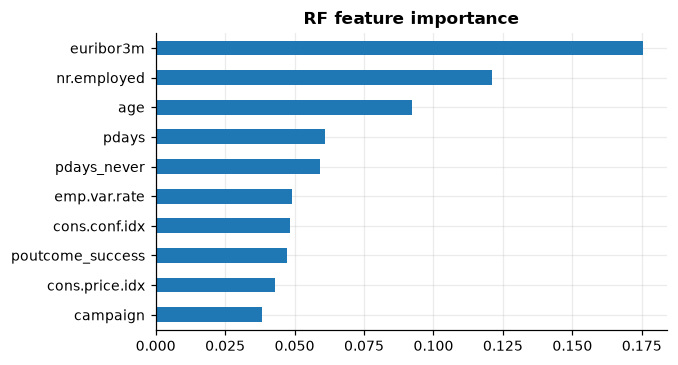

In [ ]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
rf_c = RandomForestClassifier(n_estimators=200, max_features="sqrt", min_samples_leaf=5, oob_score=True,
                              n_jobs=-1, random_state=42).fit(Xc_tr, yc_tr)
eval_clf("Random Forest (200 trees)", yc_te, rf_c.predict(Xc_te), rf_c.predict_proba(Xc_te)[:, 1], rf_c.score(Xc_tr, yc_tr))
print("OOB accuracy:", round(rf_c.oob_score_, 4))
rf_r = RandomForestRegressor(n_estimators=200, max_features=0.5, min_samples_leaf=5, n_jobs=-1, random_state=42).fit(Xr_tr, yr_tr)
eval_reg("Random Forest Regressor", yr_te, rf_r.predict(Xr_te))
pd.Series(rf_c.feature_importances_, index=Xc.columns).nlargest(10).sort_values().plot.barh(title="RF feature importance", figsize=(6, 3.5)); plt.show()

**Explanation**

- Random Forest is bagging plus feature randomness: every split considers only a random subset of the columns (max_features).
- This makes the trees more diverse than plain bagging, so their errors cancel better when combined.
- Key hyperparameters: n_estimators=200 trees, max_features='sqrt', min_samples_leaf=5, n_jobs=-1 for parallelism, random_state for reproducibility.
- The out-of-bag score validates the forest without needing a separate validation set.
- The regressor averages tree outputs, while the classifier votes; feature importance shows which inputs matter most.
- Compare its AUC with the single tree and with plain bagging in the final tables to judge the benefit of feature randomness.

In [ ]:
rows = []
for n_est in [10, 50, 100, 200]:
    for msl in [1, 5, 20]:
        m = RandomForestClassifier(n_estimators=n_est, min_samples_leaf=msl, n_jobs=-1, random_state=42).fit(Xc_tr, yc_tr)
        rows.append(dict(n_estimators=n_est, min_samples_leaf=msl, test_acc=m.score(Xc_te, yc_te), auc=roc_auc_score(yc_te, m.predict_proba(Xc_te)[:, 1])))
display(pd.DataFrame(rows).pivot(index="n_estimators", columns="min_samples_leaf", values="auc").round(4))

min_samples_leaf,1,5,20
n_estimators,,,
10,0.7514,0.7979,0.8062
50,0.7761,0.8048,0.8079
100,0.7782,0.8035,0.8071
200,0.7811,0.8022,0.8071


**Explanation**

- This grid varies the two most influential Random Forest hyperparameters: number of trees and minimum leaf size.
- More trees steadily improve AUC and then level off, since extra trees only reduce variance up to a point.
- Larger min_samples_leaf smooths the trees and often improves generalisation on noisy data like this.
- Each cell shows test AUC, so the best combination is easy to read off.
- Such a sweep is a manual form of hyperparameter tuning and costs only more compute, not more data.

## 16. Boosting / AdaBoost

AdaBoost Classifier            acc=0.8991 prec=0.700 rec=0.183 f1=0.290 auc=0.805 loss=0.370


AdaBoost Regressor               MSE=   121781.7  MAE= 300.32  R2=-0.7480


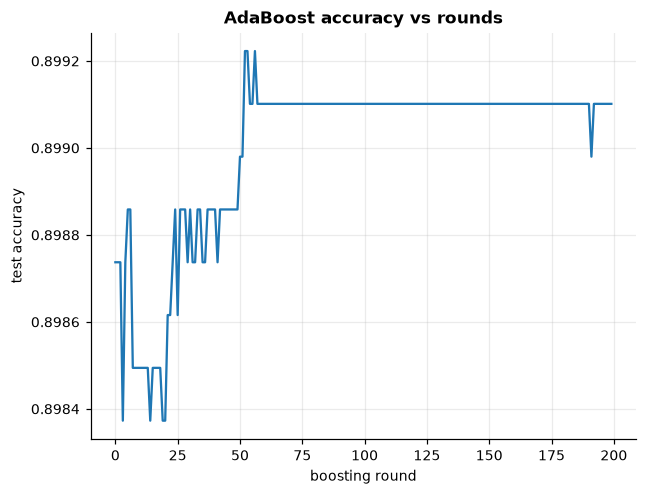

In [ ]:
from sklearn.ensemble import AdaBoostClassifier, AdaBoostRegressor
ada_c = AdaBoostClassifier(DecisionTreeClassifier(max_depth=2), n_estimators=200, learning_rate=0.5, random_state=42).fit(Xc_tr, yc_tr)
eval_clf("AdaBoost Classifier", yc_te, ada_c.predict(Xc_te), ada_c.predict_proba(Xc_te)[:, 1], ada_c.score(Xc_tr, yc_tr))
ada_r = AdaBoostRegressor(DecisionTreeRegressor(max_depth=4), n_estimators=100, learning_rate=0.5, random_state=42).fit(Xr_tr, yr_tr)
eval_reg("AdaBoost Regressor", yr_te, ada_r.predict(Xr_te))
stage = [accuracy_score(yc_te, p) for p in ada_c.staged_predict(Xc_te)]
plt.plot(stage); plt.xlabel("boosting round"); plt.ylabel("test accuracy"); plt.title("AdaBoost accuracy vs rounds"); plt.show()

**Explanation**

- AdaBoost trains weak learners (shallow trees) one after another, unlike bagging where trees are trained independently.
- After each round, misclassified samples receive larger weights, so the next learner concentrates on the hard cases.
- The final prediction is a weighted vote (classification) or weighted combination (regression) of all learners.
- learning_rate shrinks each learner's contribution; with n_estimators it balances speed against over-fitting.
- The staged curve shows how test accuracy evolves as learners are added.
- Because it is sequential, AdaBoost cannot be parallelised across learners like Random Forest.

## 17. Voting

In [ ]:
from sklearn.ensemble import VotingClassifier, VotingRegressor
from sklearn.pipeline import make_pipeline

vote_c = VotingClassifier([("lr", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
                           ("rf", RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42)),
                           ("ada", AdaBoostClassifier(DecisionTreeClassifier(max_depth=2), n_estimators=100, learning_rate=0.5, random_state=42))],
                          voting="soft").fit(Xc_tr, yc_tr)
eval_clf("Voting Classifier (soft)", yc_te, vote_c.predict(Xc_te), vote_c.predict_proba(Xc_te)[:, 1], vote_c.score(Xc_tr, yc_tr))

vote_r = VotingRegressor([("lr", make_pipeline(StandardScaler(), LinearRegression())),
                          ("rf", RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42)),
                          ("dt", DecisionTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=42))]).fit(Xr_tr, yr_tr)
eval_reg("Voting Regressor (average)", yr_te, vote_r.predict(Xr_te))

Voting Classifier (soft)       acc=0.8993 prec=0.674 rec=0.207 f1=0.317 auc=0.808 loss=0.285


Voting Regressor (average)       MSE=    52598.8  MAE= 148.00  R2=0.2450


**Explanation**

- Voting combines different kinds of models (a heterogeneous ensemble) trained on the same data.
- For classification, soft voting averages predicted probabilities; hard voting would count class labels (majority vote).
- For regression, VotingRegressor simply averages the predictions of its members.
- Pipelines let the linear models scale their own inputs while trees use the raw features.
- Models with different error patterns tend to correct each other, so the ensemble is often better than most single members.

## 18. Stacking

In [ ]:
from sklearn.ensemble import StackingClassifier, StackingRegressor
stack_c = StackingClassifier([("rf", RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42)),
                              ("dt", DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42)),
                              ("svm", make_pipeline(StandardScaler(), LinearSVC(max_iter=5000)))],
                             final_estimator=LogisticRegression(max_iter=1000), cv=3, n_jobs=-1).fit(Xc_tr, yc_tr)
eval_clf("Stacking Classifier", yc_te, stack_c.predict(Xc_te), stack_c.predict_proba(Xc_te)[:, 1], stack_c.score(Xc_tr, yc_tr))

stack_r = StackingRegressor([("rf", RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42)),
                             ("dt", DecisionTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=42)),
                             ("ada", AdaBoostRegressor(DecisionTreeRegressor(max_depth=4), n_estimators=50, random_state=42))],
                            final_estimator=LinearRegression(), cv=3, n_jobs=-1).fit(Xr_tr, yr_tr)
eval_reg("Stacking Regressor", yr_te, stack_r.predict(Xr_te))
print("Meta-learner weights (regression):", dict(zip(["rf", "dt", "ada"], stack_r.final_estimator_.coef_.round(3))))

Stacking Classifier            acc=0.9017 prec=0.665 rec=0.256 f1=0.370 auc=0.808 loss=0.271


Stacking Regressor               MSE=    52384.9  MAE= 147.18  R2=0.2481
Meta-learner weights (regression): {'rf': np.float64(0.442), 'dt': np.float64(0.511), 'ada': np.float64(0.017)}


**Explanation**

- Stacking uses the predictions of several base models as input features for a second-layer meta learner.
- To avoid leakage, the base predictions given to the meta model come from 3-fold cross-validation on the training set.
- Here the meta learner is Logistic Regression for classification and Linear Regression for regression.
- The printed coefficients show how much the linear meta model trusts each base regressor.
- Unlike voting with fixed equal weights, stacking learns the best way to combine the models from data.

## 19. Final model comparison

,MSE,MAE,R2
BaggingRegressor (50 trees),52126.037,146.747,0.252
Stacking Regressor,52384.946,147.180,0.248
Voting Regressor (average),52598.804,147.996,0.245
Decision Tree Reg depth=6,52857.370,147.987,0.241
Random Forest Regressor,53002.017,148.308,0.239
Decision Tree Reg depth=4,53116.654,148.482,0.238
Decision Tree Reg depth=8,53182.864,148.054,0.237
Decision Tree Reg depth=2,54511.986,151.648,0.218
Regression Tree (scratch CART),55296.264,152.119,0.206
Linear Regression (sklearn),56845.821,155.625,0.184


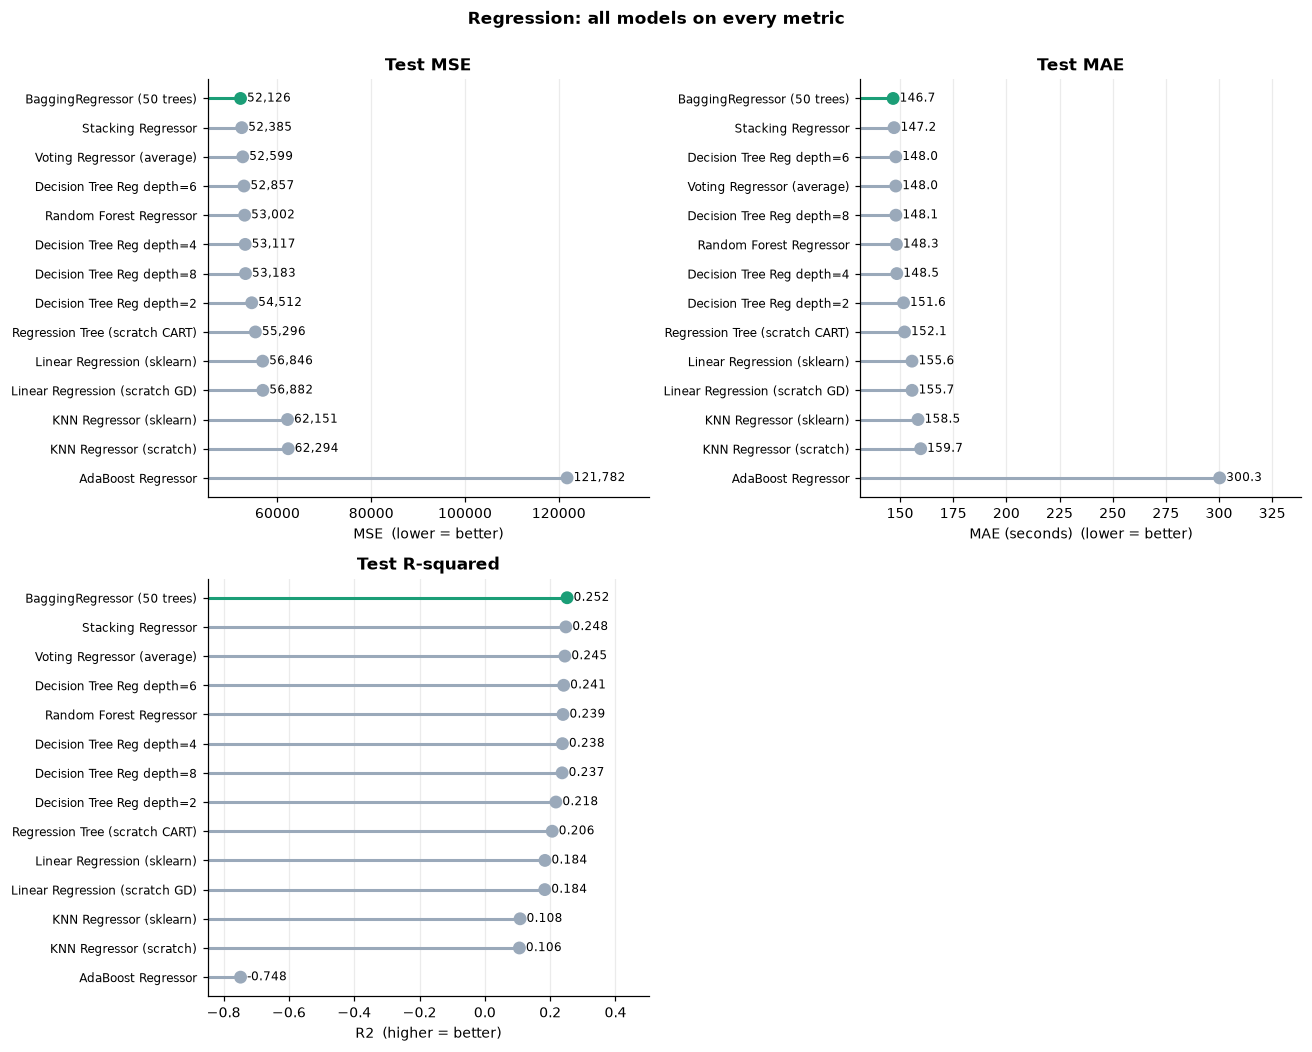

In [ ]:
R = pd.DataFrame(reg_results).T[REG_COLS].astype(float)
display(R.sort_values("MSE").round(3))
fig, ax = plt.subplots(2, 2, figsize=(12, 9.5)); ax = ax.ravel(); ax[3].axis("off")
rank_dot(ax[0], R["MSE"], "Test MSE", "MSE", higher_better=False, fmt="{:,.0f}")
rank_dot(ax[1], R["MAE"], "Test MAE", "MAE (seconds)", higher_better=False, fmt="{:.1f}")
rank_dot(ax[2], R["R2"], "Test R-squared", "R2", higher_better=True)
fig.suptitle("Regression: all models on every metric", fontweight="bold", y=1.0); plt.tight_layout(); plt.show()

**Explanation**

- The table and the three panels cover every regression model: scratch, library, KNN, bagging, Random Forest, AdaBoost, voting and stacking.
- Each panel ranks the models on one metric, and the best model on that metric is highlighted in green.
- A model that is best on MSE is usually also best on MAE and R2; differences between metrics reveal outlier sensitivity.
- AdaBoost Regressor is far behind because its re-weighting chases the heavy-tailed long calls.
- The ensembles (bagging, voting, stacking) sit at the top, but their lead over a single depth-6 tree is small.

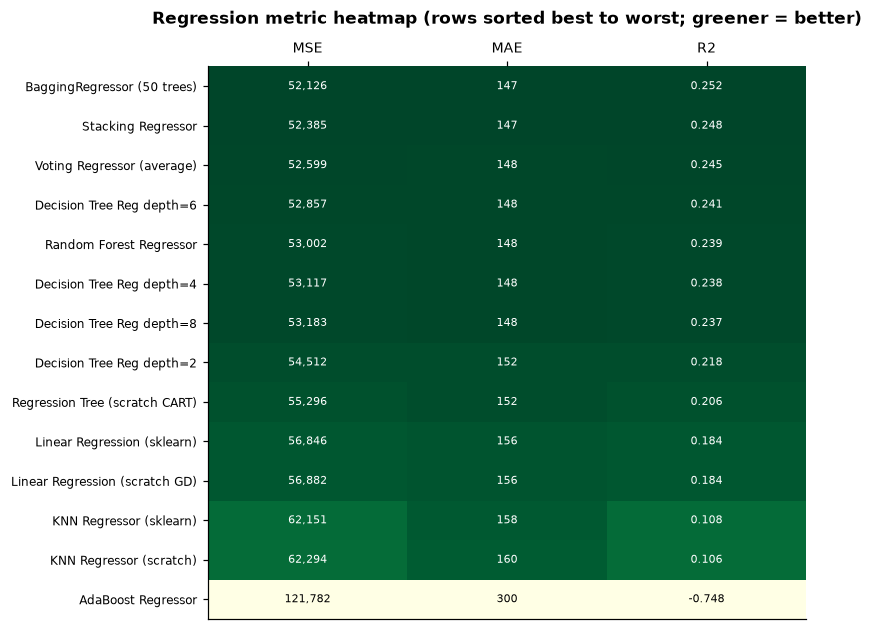

In [ ]:
Rg = R.loc[composite(R, REG_LOWER).index]
fig, ax = plt.subplots(figsize=(7.5, 0.3 * len(Rg) + 1.6))
heatmap(ax, Rg, REG_LOWER, "Regression metric heatmap (rows sorted best to worst; greener = better)")
plt.tight_layout(); plt.show()

**Explanation**

- The heatmap shows every regression metric for every model in one picture; greener cells are better.
- Colours are normalised within each column, and MSE and MAE are inverted so green always means good.
- Rows are sorted by average rank across the three metrics, so the best model is on top.
- Because all metrics agree on the ordering for most models, the ranking is stable and not an artefact of one metric.
- The numbers inside the cells are the real test-set values, so the picture and the table never disagree.

,Accuracy,Precision,Recall,F1,AUC,Loss
BaggingClassifier (50 trees),0.9012,0.6549,0.2597,0.3719,0.8145,0.2648
Stacking Classifier,0.9017,0.6648,0.2565,0.3701,0.8075,0.2707
Manual Bagging (25 trees),0.9008,0.6572,0.2500,0.3622,0.8113,0.2664
"Decision Tree (sklearn, depth 5)",0.9013,0.6550,0.2619,0.3741,0.7913,0.2713
Random Forest (200 trees),0.9006,0.6580,0.2446,0.3566,0.8022,0.2693
Single deep tree (depth 8),0.8987,0.6158,0.2694,0.3748,0.8039,0.2756
Voting Classifier (soft),0.8993,0.6737,0.2069,0.3166,0.8082,0.2847
LinearSVC (sklearn),0.8993,0.6800,0.2015,0.3109,0.7966,0.2785
Logistic Regression (sklearn),0.8984,0.6522,0.2101,0.3178,0.7998,0.2741
AdaBoost Classifier,0.8991,0.6996,0.1832,0.2904,0.8048,0.3702


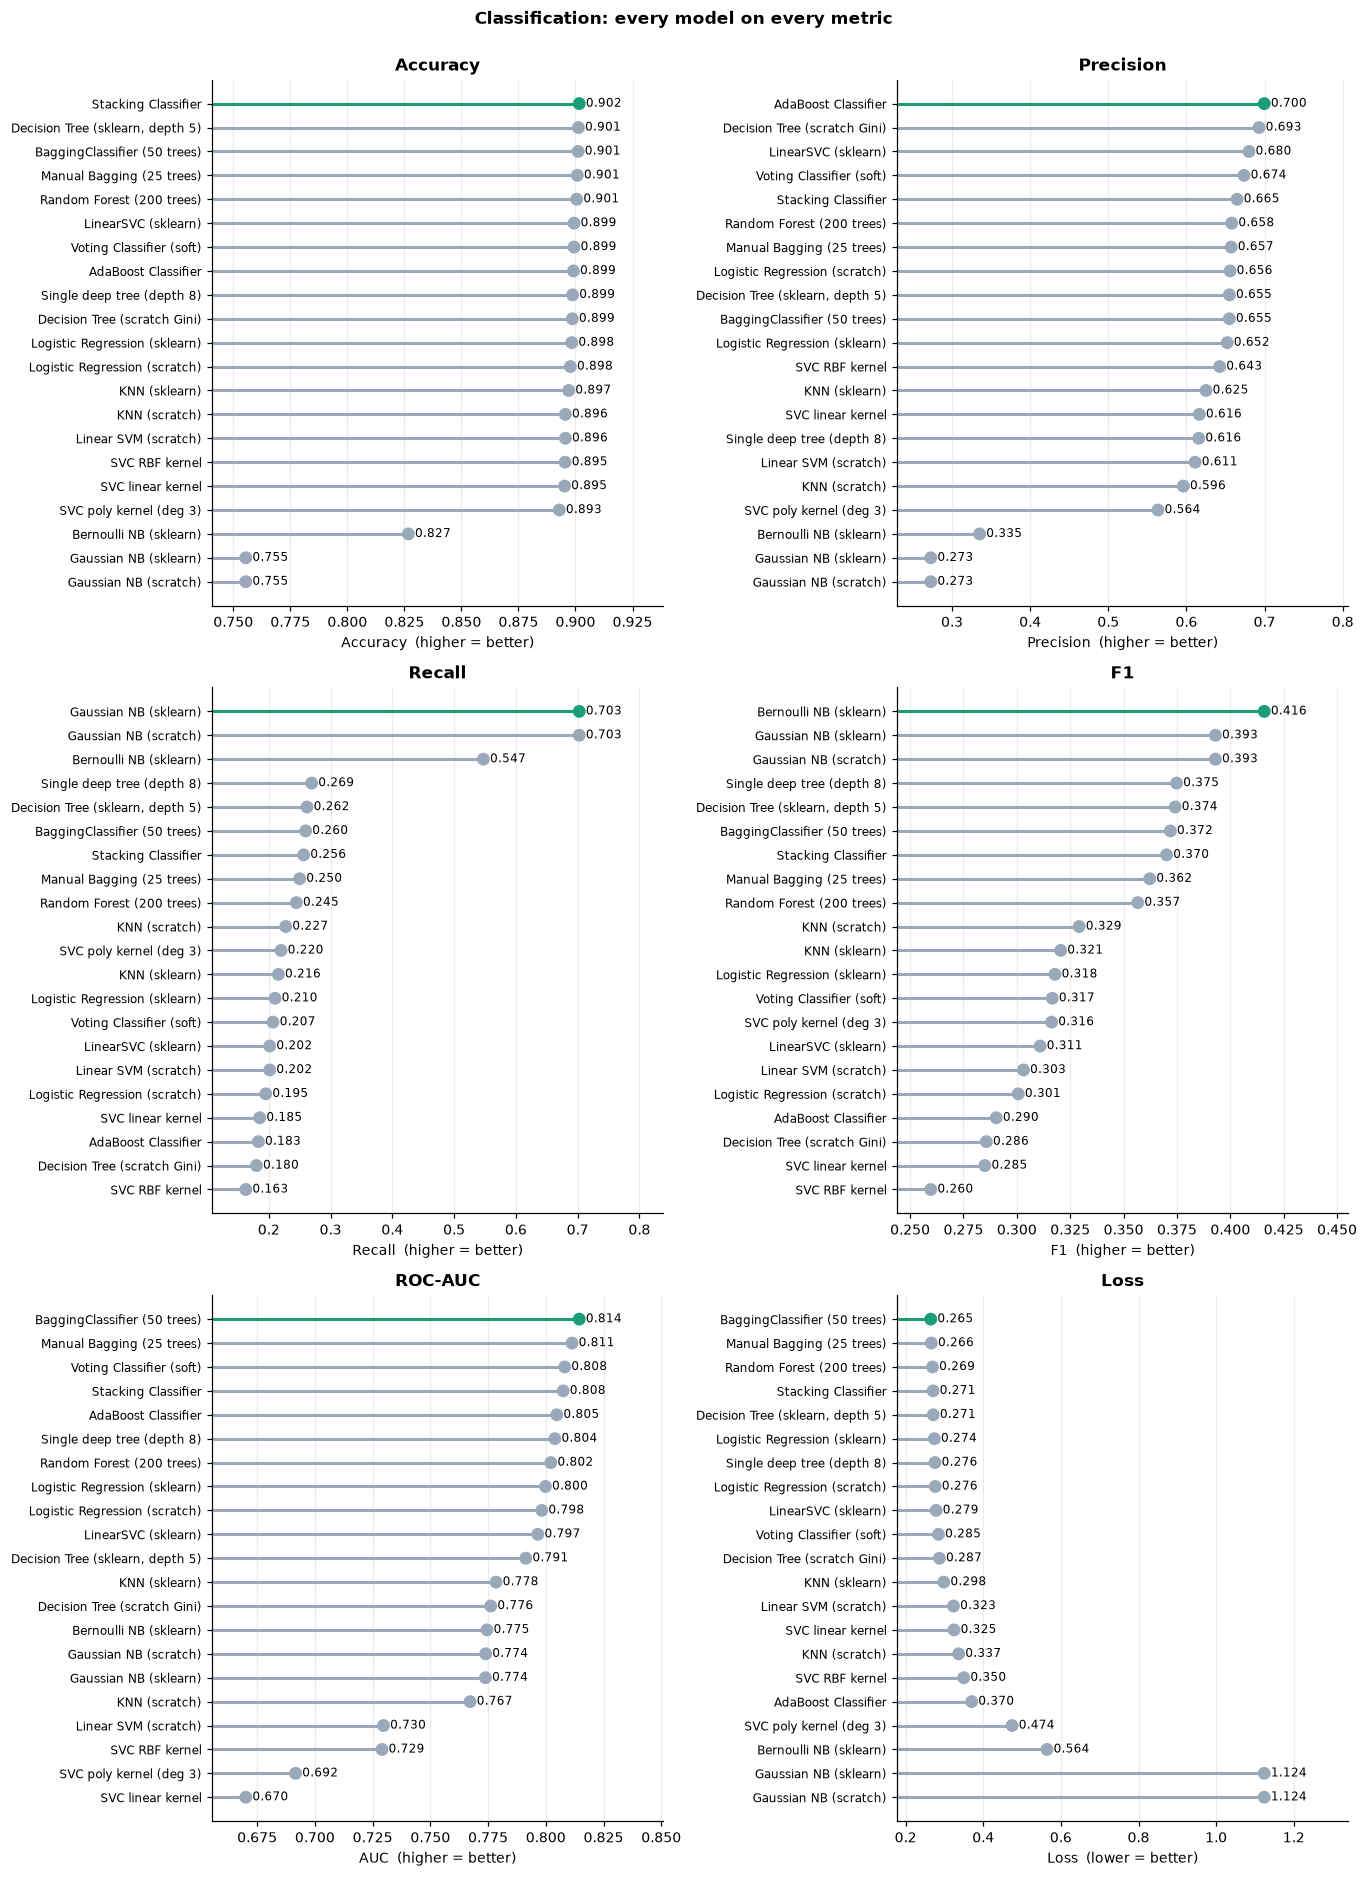

In [ ]:
C_ = pd.DataFrame(clf_results).T[CLF_COLS].astype(float)
display(C_.loc[composite(C_, CLF_LOWER).index].round(4))
fig, ax = plt.subplots(3, 2, figsize=(12.5, 17))
for a, c in zip(ax.ravel(), CLF_COLS):
    rank_dot(a, C_[c], {"AUC": "ROC-AUC"}.get(c, c), c, higher_better=(c not in CLF_LOWER))
fig.suptitle("Classification: every model on every metric", fontweight="bold", y=1.0); plt.tight_layout(); plt.show()

**Explanation**

- The table lists accuracy, precision, recall, F1, ROC-AUC and loss for all classifiers, sorted by average rank.
- Each panel ranks all models on one metric, with the best highlighted in green.
- Accuracy panels show tiny gaps because predicting 'no' for everyone already scores about 89%, so the other metrics are more informative.
- Recall and precision pull in opposite directions: Naive Bayes wins recall but loses precision, while the trees and SVMs do the reverse.
- The loss panel separates well-calibrated models (logistic, bagging, stacking, about 0.27) from over-confident ones (Naive Bayes at 1.12, AdaBoost, polynomial SVM).

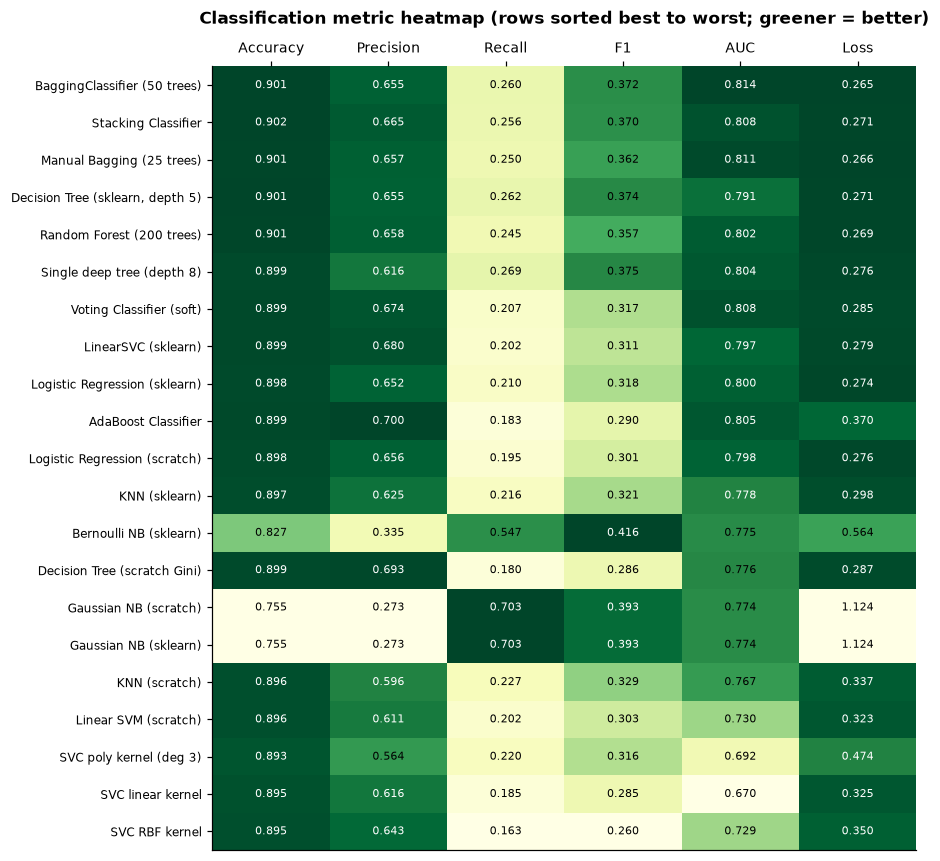

In [ ]:
Cg = C_.loc[composite(C_, CLF_LOWER).index]
fig, ax = plt.subplots(figsize=(8.5, 0.3 * len(Cg) + 1.6))
heatmap(ax, Cg, CLF_LOWER, "Classification metric heatmap (rows sorted best to worst; greener = better)")
plt.tight_layout(); plt.show()

**Explanation**

- This heatmap puts all six classification metrics for all models into one view, greener meaning better.
- Loss is inverted so that a low loss is shown in green, like the other metrics.
- Rows are ordered by average rank, so the top rows are the models that are consistently good rather than good on one metric only.
- Vertical stripes show which metric separates models; vertical stripes of similar colour (accuracy) show a metric that does not.
- The cell values are the real test-set numbers from the executed code.

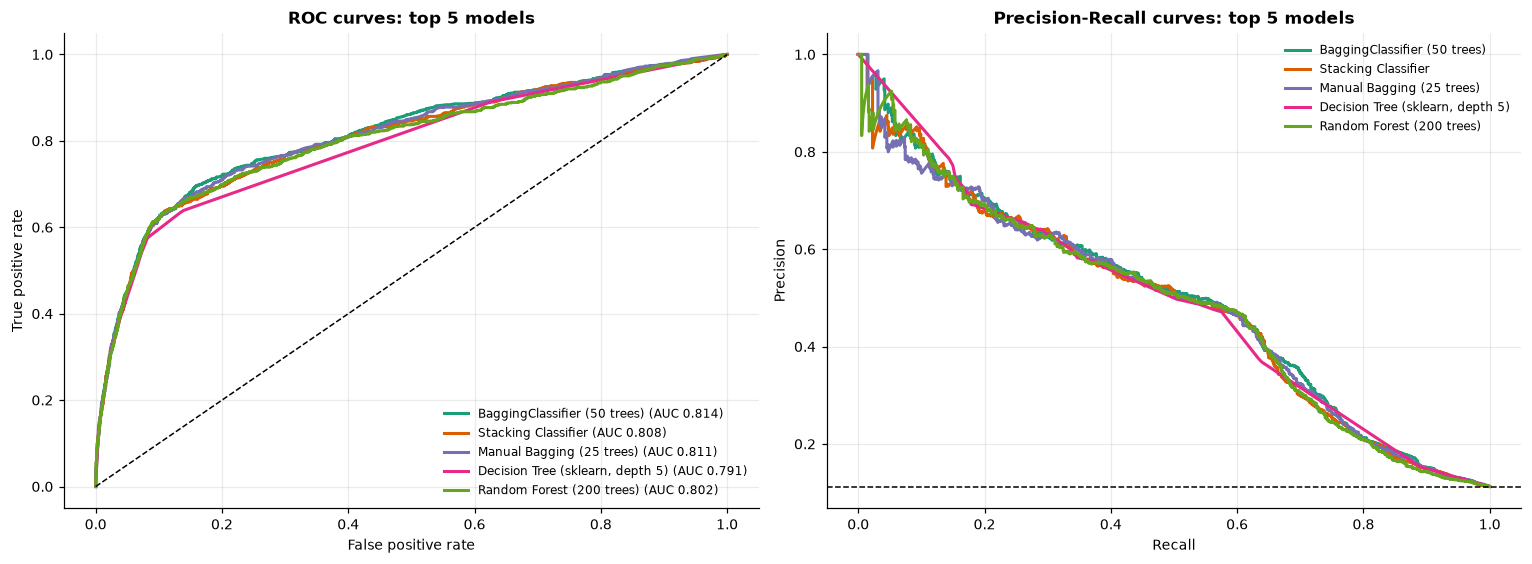

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve, auc
top5 = list(composite(C_, CLF_LOWER).index[:5])
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
for i, nm in enumerate(top5):
    fpr, tpr, _ = roc_curve(yc_te, clf_scores[nm]); ax[0].plot(fpr, tpr, lw=2, color=PALETTE[i], label=f"{nm} (AUC {auc(fpr, tpr):.3f})")
    p, r, _ = precision_recall_curve(yc_te, clf_scores[nm]); ax[1].plot(r, p, lw=2, color=PALETTE[i], label=nm)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].set_title("ROC curves: top 5 models"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].axhline(yc_te.mean(), color="k", ls="--", lw=1); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-Recall curves: top 5 models"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Explanation**

- The ROC curve plots true-positive rate against false-positive rate over all thresholds; closer to the top-left corner is better.
- The precision-recall curve is more informative here because positives are rare; the dashed line is the 11% baseline of a random guesser.
- Only the five models with the best average rank are drawn, so the curves stay readable.
- The curves are built from the stored test scores of each model, so scratch and library models are treated identically.
- Choosing a point on these curves is a business decision: more recall means contacting more customers who will say no.

## 20. Observations and conclusion

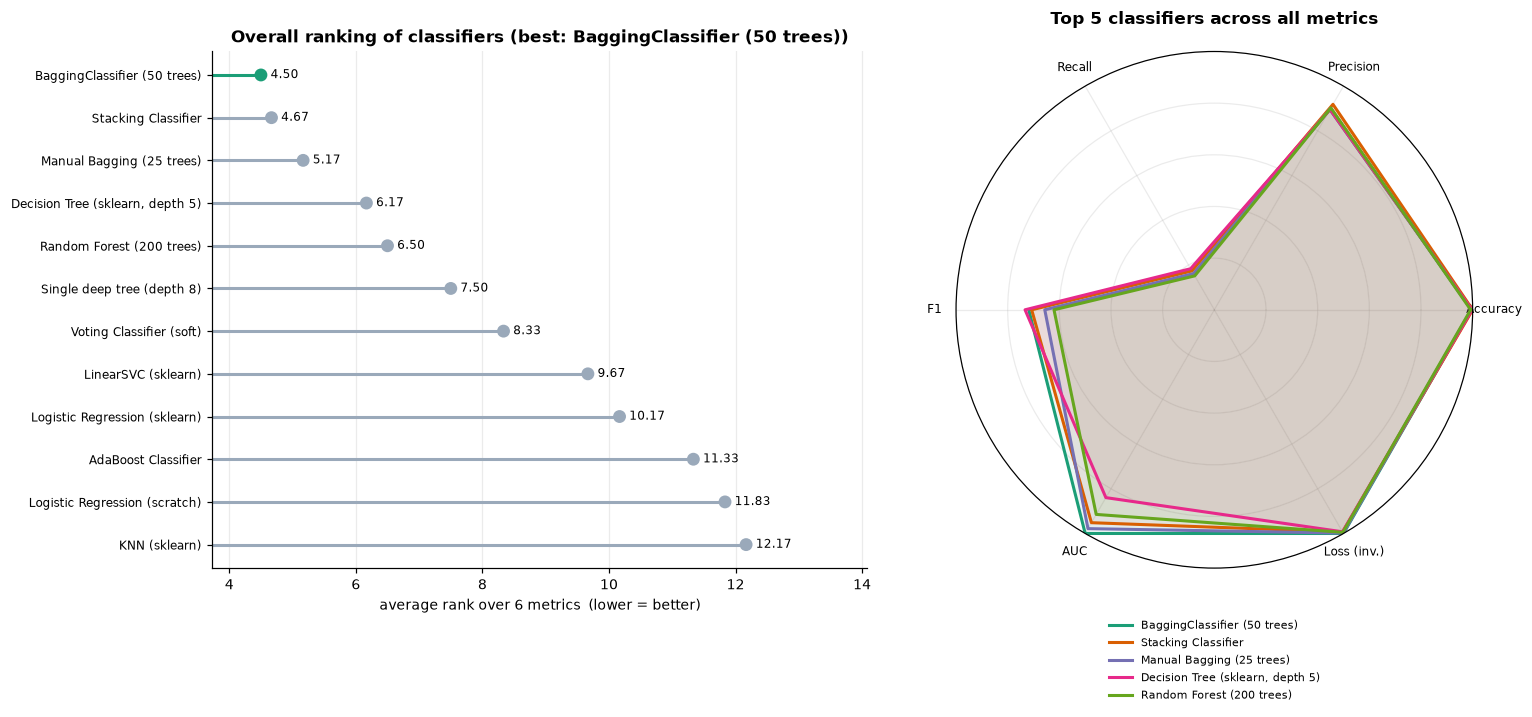

BEST CLASSIFIER: BaggingClassifier (50 trees)
Accuracy     0.9012
Precision    0.6549
Recall       0.2597
F1           0.3719
AUC          0.8145
Loss         0.2648


In [ ]:
rk = composite(C_, CLF_LOWER)
best_clf = rk.index[0]
fig = plt.figure(figsize=(14, 6.4), layout="constrained")
rank_dot(fig.add_subplot(1, 2, 1), rk, f"Overall ranking of classifiers (best: {best_clf})", "average rank over 6 metrics", higher_better=False, fmt="{:.2f}", top=12)
radar(fig.add_subplot(1, 2, 2, projection="polar"), C_, list(rk.index[:5]), CLF_LOWER, "Top 5 classifiers across all metrics")
plt.show()
print("BEST CLASSIFIER:", best_clf); print(C_.loc[best_clf].round(4).to_string())

**Explanation**

- Every classifier gets a rank on each of accuracy, precision, recall, F1, AUC and loss; the average rank decides the overall winner.
- The left chart shows the twelve best classifiers by average rank, with the winner highlighted in green and named in the title.
- The radar chart compares the top five on all six metrics at once; a larger, rounder shape means a stronger all-round model.
- Rank-based scoring prevents a single extreme metric (for example a huge loss) from deciding the result.
- The best classifier and its exact metrics are also printed, so the conclusion is generated from the executed results.

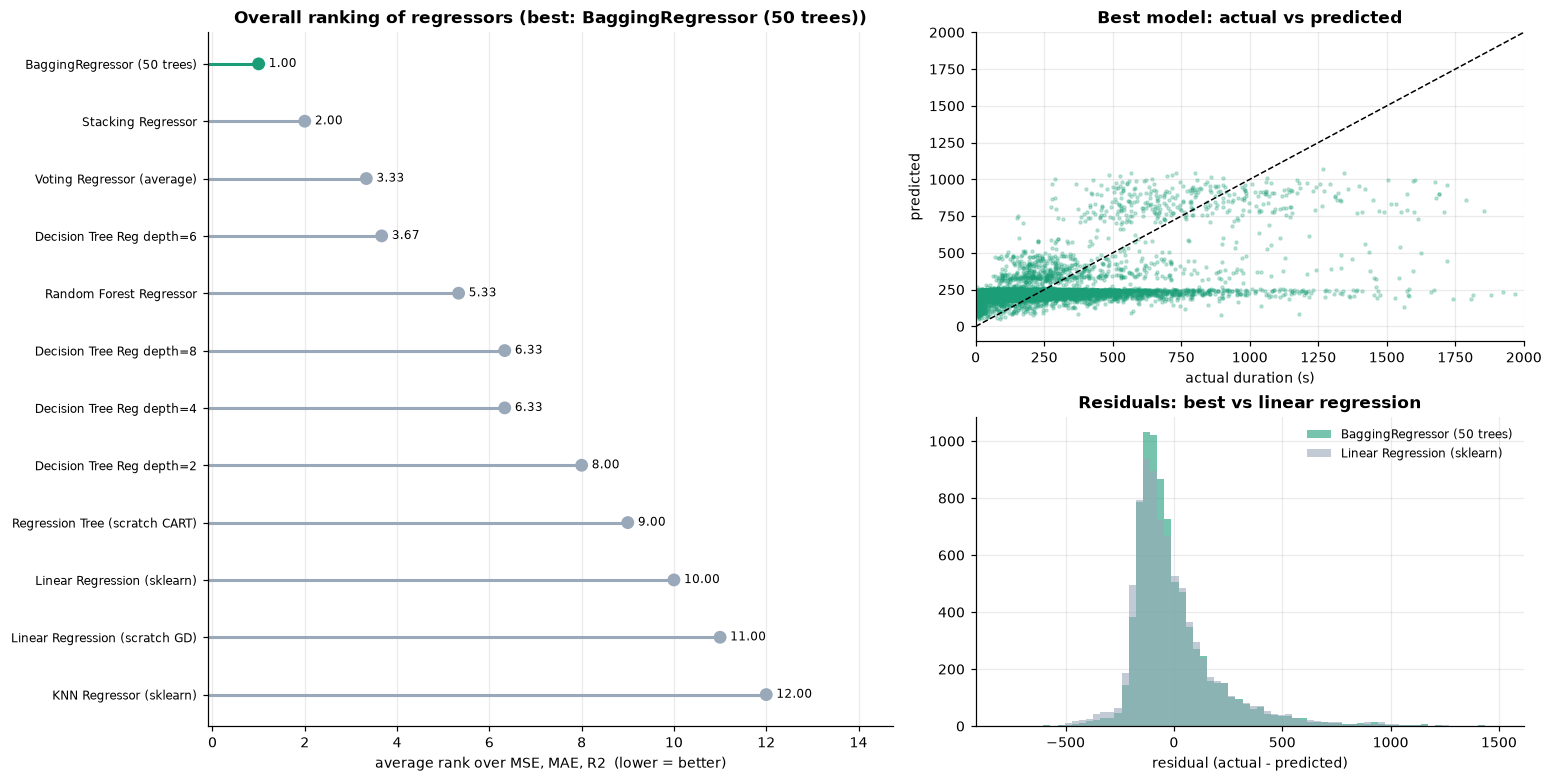

BEST REGRESSOR: BaggingRegressor (50 trees)
MSE    52126.0370
MAE      146.7470
R2         0.2518


In [ ]:
rr = composite(R, REG_LOWER)
best_reg = rr.index[0]
fig = plt.figure(figsize=(14, 7), layout="constrained"); gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1])
rank_dot(fig.add_subplot(gs[:, 0]), rr, f"Overall ranking of regressors (best: {best_reg})", "average rank over MSE, MAE, R2", higher_better=False, fmt="{:.2f}", top=12)
a1, a2 = fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])
a1.scatter(yr_te, reg_preds[best_reg], s=4, alpha=.25, color=BEST); a1.plot([0, 2000], [0, 2000], "k--", lw=1)
a1.set_xlim(0, 2000); a1.set_ylim(-100, 2000); a1.set_xlabel("actual duration (s)"); a1.set_ylabel("predicted"); a1.set_title("Best model: actual vs predicted")
for nm, col in [(best_reg, BEST), ("Linear Regression (sklearn)", REST)]:
    a2.hist(yr_te - reg_preds[nm], bins=70, alpha=.6, color=col, label=nm, range=(-800, 1500))
a2.set_xlabel("residual (actual - predicted)"); a2.set_title("Residuals: best vs linear regression"); a2.legend(fontsize=8)
plt.show()
print("BEST REGRESSOR:", best_reg); print(R.loc[best_reg].round(4).to_string())

**Explanation**

- Regression models are ranked by their average rank over MSE, MAE and R2; the winner is highlighted in green and named in the title.
- The middle panel plots the winner's predictions against the truth; the dashed diagonal marks perfect predictions.
- The right panel compares residuals of the winner and plain linear regression; a narrower histogram means smaller errors.
- Both models under-predict long calls, which confirms that duration is only partly predictable from these features.
- The best regressor and its exact metrics are printed from the executed results.

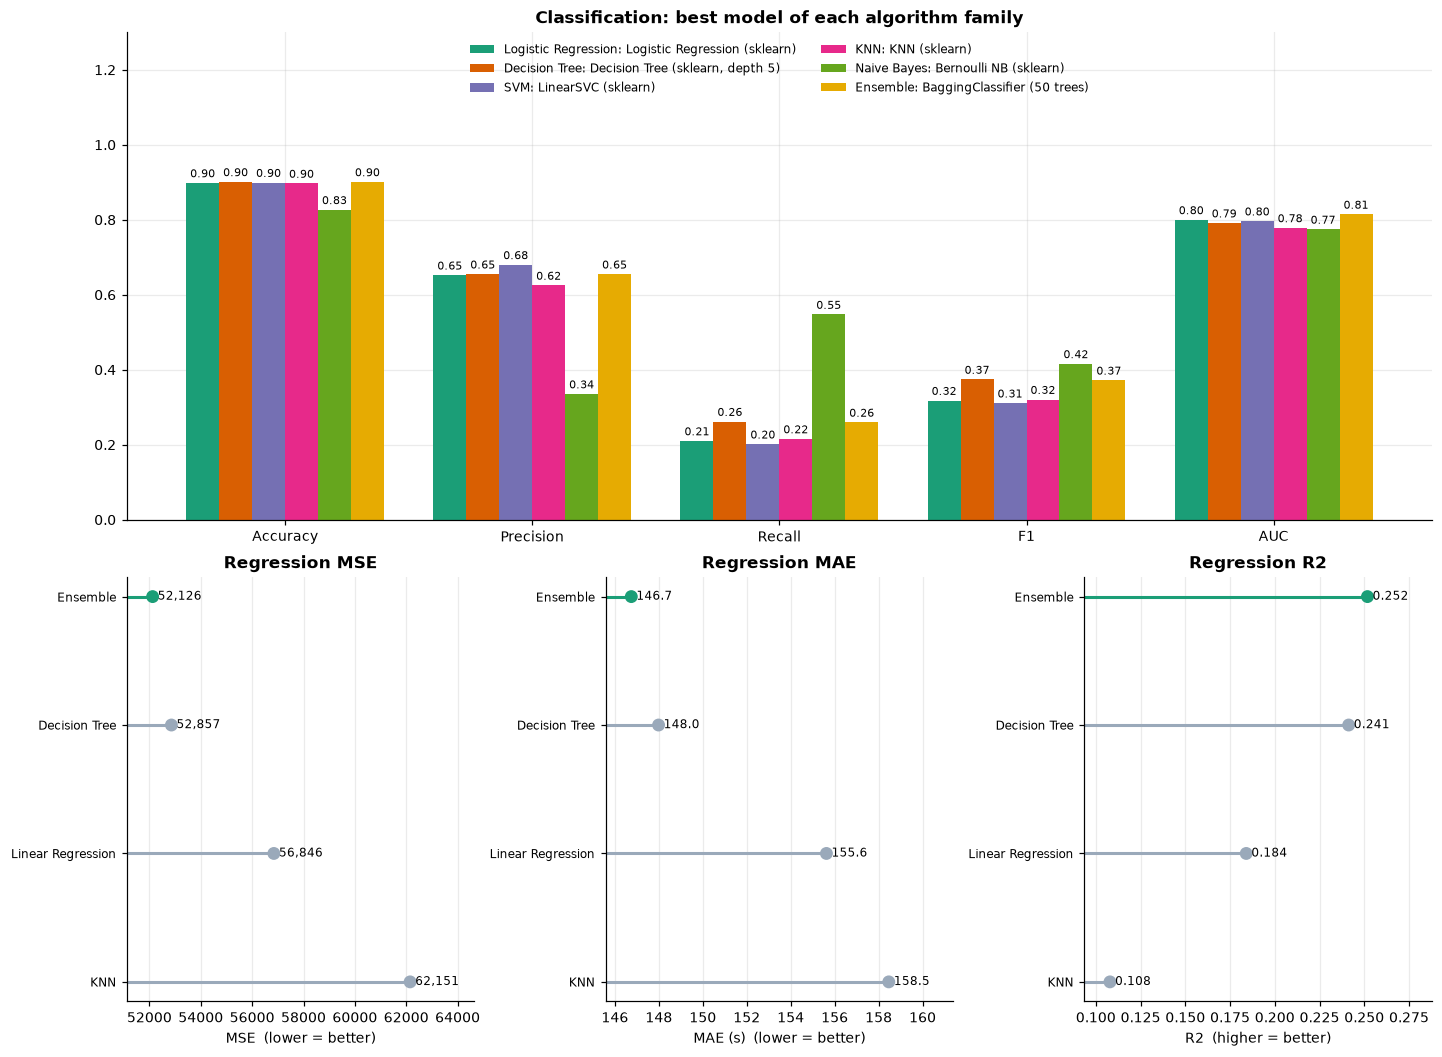

Classification family winners: {'Logistic Regression': 'Logistic Regression (sklearn)', 'Decision Tree': 'Decision Tree (sklearn, depth 5)', 'SVM': 'LinearSVC (sklearn)', 'KNN': 'KNN (sklearn)', 'Naive Bayes': 'Bernoulli NB (sklearn)', 'Ensemble': 'BaggingClassifier (50 trees)'}
Regression family winners: {'Linear Regression': 'Linear Regression (sklearn)', 'Decision Tree': 'Decision Tree Reg depth=6', 'KNN': 'KNN Regressor (sklearn)', 'Ensemble': 'BaggingRegressor (50 trees)'}


In [ ]:
cf = pd.Series({n: family(n, "clf") for n in C_.index}); rf_ = pd.Series({n: family(n, "reg") for n in R.index})
best_c = {f: composite(C_.loc[cf[cf == f].index], CLF_LOWER).index[0] for f in cf.unique()}
best_r = {f: composite(R.loc[rf_[rf_ == f].index], REG_LOWER).index[0] for f in rf_.unique()}
Cf = C_.loc[list(best_c.values())].set_axis(list(best_c.keys())); Rf = R.loc[list(best_r.values())].set_axis(list(best_r.keys()))
fig = plt.figure(figsize=(13, 9.5), layout="constrained"); gs = fig.add_gridspec(2, 3, height_ratios=[1.15, 1])
ax0 = fig.add_subplot(gs[0, :]); cols = ["Accuracy", "Precision", "Recall", "F1", "AUC"]; w = 0.8 / len(Cf)
for i, (fam, row) in enumerate(Cf.iterrows()):
    bars = ax0.bar(np.arange(len(cols)) + (i - (len(Cf) - 1) / 2) * w, row[cols].values, w, label=f"{fam}: {best_c[fam]}", color=PALETTE[i % 7])
    ax0.bar_label(bars, fmt="%.2f", fontsize=7, padding=2)
ax0.set_xticks(range(len(cols))); ax0.set_xticklabels(cols); ax0.set_ylim(0, 1.3); ax0.legend(ncol=2, fontsize=8, loc="upper center")
ax0.set_title("Classification: best model of each algorithm family")
rank_dot(fig.add_subplot(gs[1, 0]), Rf["MSE"], "Regression MSE", "MSE", False, "{:,.0f}")
rank_dot(fig.add_subplot(gs[1, 1]), Rf["MAE"], "Regression MAE", "MAE (s)", False, "{:.1f}")
rank_dot(fig.add_subplot(gs[1, 2]), Rf["R2"], "Regression R2", "R2", True)
plt.show()
print("Classification family winners:", best_c); print("Regression family winners:", best_r)

**Explanation**

- Models are grouped into algorithm families (SVM, Decision Tree, KNN, Naive Bayes, Logistic, Ensemble and so on), and the best member of each family is kept.
- The grouped bars compare the families on accuracy, precision, recall, F1 and AUC, which shows the strengths and weaknesses of each algorithm.
- The three right panels give the same family-level comparison for regression using MSE, MAE and R2.
- This answers 'which algorithm is best for which task' without being biased by how many variants of each family were trained.
- The winning model name of every family is printed below the chart.

### Suitability of each algorithm (summary)

| Algorithm | Strengths | Weaknesses | Best suited for |
|---|---|---|---|
| **SVM** | Strong margin-based generalisation; kernels give non-linear boundaries; works in high dimensions | Slow on large data (kernel SVM is quadratic); needs scaling; no native probabilities | Medium-sized, high-dimensional, well-scaled data where a clear margin exists |
| **Decision Tree** | Easy to interpret; no scaling; handles mixed features and non-linear rules | Over-fits when deep; unstable to small data changes | Cases where explainable rules are needed |
| **KNN** | No training; simple; flexible local decision boundary | Slow prediction; sensitive to scaling and irrelevant features; weak on imbalanced data | Small/medium low-dimensional data with meaningful distances |
| **Naive Bayes** | Very fast; works with little data; high recall on rare classes | Independence assumption is unrealistic; over-confident probabilities | Text/spam filtering, quick baselines, cases where finding positives matters more than precision |
| **Logistic Regression** | Fast, well-calibrated probabilities, interpretable coefficients | Only linear boundaries | Baseline and risk scoring |
| **Ensembles** | Reduce variance (bagging/RF) or bias (boosting); best overall accuracy on tabular data | Less interpretable; more compute | Tabular problems where predictive performance matters most |

In [ ]:
pd.DataFrame(reg_results).T.to_csv("regression_results.csv"); pd.DataFrame(clf_results).T.to_csv("classification_results.csv")
summary = pd.DataFrame({"Task": ["Classification", "Regression"], "Best model": [best_clf, best_reg],
                        "Headline metric": [f"AUC {C_.loc[best_clf, 'AUC']:.3f}, F1 {C_.loc[best_clf, 'F1']:.3f}, loss {C_.loc[best_clf, 'Loss']:.3f}",
                                            f"MSE {R.loc[best_reg, 'MSE']:,.0f}, MAE {R.loc[best_reg, 'MAE']:.1f}, R2 {R.loc[best_reg, 'R2']:.3f}"]})
display(summary)

,Task,Best model,Headline metric
0,Classification,BaggingClassifier (50 trees),"AUC 0.814, F1 0.372, loss 0.265"
1,Regression,BaggingRegressor (50 trees),"MSE 52,126, MAE 146.7, R2 0.252"


**Explanation**

- The final cell saves both result tables as CSV files so they can be reused in the report.
- It then builds a one-row-per-task summary naming the best classifier and the best regressor, taken directly from the computed rankings.
- Classification winners are decided by consistency across six metrics, not by accuracy alone, because the target is imbalanced.
- Regression winners are decided across MSE, MAE and R2, which together capture large errors, typical errors and explained variance.
- Overall: ensembles give small but consistent gains, simple models are nearly as good, and scratch implementations agree with library ones.